# Linear Regression - Start

In [11]:
# import the necessary packages
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
 
sns.set(style='darkgrid')

## 2D simulation data

In [39]:
import plotly.graph_objects as go

rng = np.random.RandomState(10)
X = 10 * rng.rand(1000, 2)  # feature matrix
y = 50.9 + np.dot(X, [2.2, 4.])  # target vector

In [34]:
X.shape

(1000, 2)

In [35]:
y.shape

(1000,)

In [40]:
noise = 3 * np.random.randn(len(X))

In [41]:
y_noise = y + noise

In [42]:
fig = go.Figure()
data_scatter = go.Scatter3d(x=X[:,0], y=X[:,1], z=y, 
                            mode="markers",
                            marker=dict(size=2))
fig.add_trace(data_scatter)
fig.update_layout(margin=dict(l=0, r=0, t=0, b=0), 
                  height=600)
fig

In [43]:
fig = go.Figure()
data_scatter = go.Scatter3d(x=X[:,0], y=X[:,1], z=y_noise, 
                            mode="markers",
                            marker=dict(size=2))
fig.add_trace(data_scatter)
fig.update_layout(margin=dict(l=0, r=0, t=0, b=0), 
                  height=600)
fig

## Using the normal equations

using the normal equations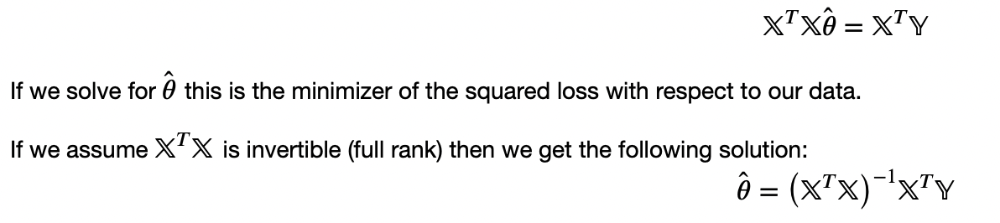

In [44]:
from numpy.linalg import inv, solve
def least_squares_by_inv(X, Y):
    return inv(X.T @ X) @ X.T @ Y
    
def least_squares_by_solve(X, Y):
    return solve(X.T @ X, X.T @ Y)


In [47]:
def add_ones_column(X):
    return np.hstack([np.ones((X.shape[0],1)), X])

In [48]:
XX=add_ones_column(X)
XX

array([[1.        , 7.71320643, 0.20751949],
       [1.        , 6.33648235, 7.48803883],
       [1.        , 4.98507012, 2.24796646],
       ...,
       [1.        , 5.29891438, 9.16150193],
       [1.        , 4.96950438, 4.56259681],
       [1.        , 9.46956812, 0.37962079]])

In [49]:
Y=y_noise.copy()
theta_hat = least_squares_by_inv(XX,Y)
theta_hat

array([51.26998234,  2.18719162,  3.95575186])

In [50]:
theta_hat = least_squares_by_solve(XX,Y)
theta_hat

array([51.26998234,  2.18719162,  3.95575186])

In [51]:
def plot_plane(f, X, grid_points = 30):
    u = np.linspace(X[:,0].min(),X[:,0].max(), grid_points)
    v = np.linspace(X[:,1].min(),X[:,1].max(), grid_points)
    xu, xv = np.meshgrid(u,v)
    X = np.vstack((xu.flatten(),xv.flatten())).transpose()
    z = f(X)
    return go.Surface(x=xu, y=xv, z=z.reshape(xu.shape),opacity=0.8)

In [53]:
def model_append_ones(X):
    return add_ones_column(X) @ theta_hat

In [54]:
fig = go.Figure()
fig.add_trace(data_scatter)
fig.add_trace(plot_plane(model_append_ones, X))
fig.update_layout(margin=dict(l=0, r=0, t=0, b=0), 
                  height=600)

## Using our own SGD implementation

In [13]:
def stochastic_gradient_descent(X, y, alpha=0.01, epochs=100, batch_size=1):
    """
    :param X: feature vector
    :param y: target vector
    :param alpha: learning rate (default=0.01)
    :param epochs: maximum number of iterations of the linear regression 
                         algorithm for a single run (default=100)
    :param batch_size: the portion of the mini-batch (default=1)
    :return: weights, list of cost function changing overtime
    """
 
    m = np.shape(X)[0]  # total number of samples
    n = np.shape(X)[1]  # total number of features
 
    X = np.concatenate((np.ones((m, 1)), X), axis=1)
    W = np.random.randn(n + 1, )
 
    # stores the updates on the lost/cost function
    cost_history_list = []
    # iterate until the maximum number of epochs
    for current_iteration in np.arange(epochs):  # begin the process
 
        # save the total lost/cost during each batch
        batch_epoch_loss_list = []
 
        for (X_batch, y_batch) in next_batch(X, y, batch_size):
            # current size of the feature batch
            batch_m = np.shape(X_batch)[0]
 
            # compute the dot product between our
            # feature 'X_batch' and weight 'W'
            y_estimated = X_batch.dot(W)
 
            # calculate the difference between the actual
            # and estimated value
            error = y_estimated - y_batch
 
            # get the cost (Mean squared error -MSE)
            cost = (1 / 2 * m) * np.sum(error ** 2)
 
            batch_epoch_loss_list.append(cost)  # save it to a list
 
            # Update our gradient by the dot product between the
            # transpose of 'X_batch' and our error divided by the
            # few number of samples
            gradient = (1 / batch_m) * X_batch.T.dot(error)
 
            # Now we have to update our weights
            W = W - alpha * gradient
 
        # Let's print out the cost to see how these values
        # changes after every each iteration
        print(f"cost:{np.average(batch_epoch_loss_list)} \t"
              f" iteration: {current_iteration}")
 
        # keep track of the cost
        cost_history_list.append(np.average(batch_epoch_loss_list))
 
    # return both our weight and list of cost function changing overtime
    return W, cost_history_list

In [12]:
def next_batch(features, labels, batch_size):
    """
    :param features: feature matrix
    :param labels: target vector
    :param batch_size:  size of mini-batch 
    :return: a list of the current batched features and labels
    """
    batch_list = []
    # iterate though a mini batch of both our features and labels
    for data in np.arange(start=0, stop=np.shape(features)[0], step=batch_size):
        # append the current batched features and labels in a list
        batch_list.append((features[data: data + batch_size],
                           labels[data: data + batch_size]))
 
    return batch_list


In [65]:
# calls the stochastic gradient descent method
weight, cost_history_list = stochastic_gradient_descent(X, Y,
                                                        alpha=0.01,
                                                        epochs=100,
                                                        batch_size=64)

cost:24074273.595119253 	 iteration: 0
cost:11215260.859803125 	 iteration: 1
cost:10715371.924382292 	 iteration: 2
cost:10238252.234664418 	 iteration: 3
cost:9782911.228845393 	 iteration: 4
cost:9348403.37539865 	 iteration: 5
cost:8933789.189500086 	 iteration: 6
cost:8538161.195075382 	 iteration: 7
cost:8160650.7331017135 	 iteration: 8
cost:7800428.26876178 	 iteration: 9
cost:7456702.10194135 	 iteration: 10
cost:7128716.754205063 	 iteration: 11
cost:6815751.338350955 	 iteration: 12
cost:6517117.980918674 	 iteration: 13
cost:6232160.311782589 	 iteration: 14
cost:5960252.021693835 	 iteration: 15
cost:5700795.4855950065 	 iteration: 16
cost:5453220.4489176255 	 iteration: 17
cost:5216982.774030657 	 iteration: 18
cost:4991563.244097728 	 iteration: 19
cost:4776466.421716696 	 iteration: 20
cost:4571219.559833247 	 iteration: 21
cost:4375371.5625345595 	 iteration: 22
cost:4188491.9934385084 	 iteration: 23
cost:4010170.129498576 	 iteration: 24
cost:3840014.058144413 	 iter

In [67]:
weight

array([46.45530836,  2.68966302,  4.39437897])

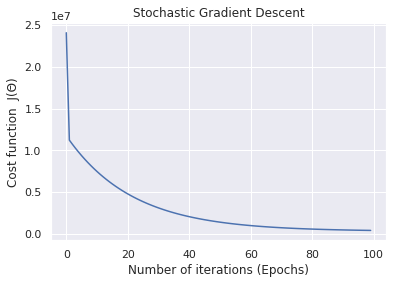

In [66]:
# visualize how our cost decreases over time
plt.plot(np.arange(len(cost_history_list)), cost_history_list)
plt.xlabel("Number of iterations (Epochs)")
plt.ylabel("Cost function  J(Θ)")
plt.title("Stochastic Gradient Descent")
plt.show()


## 2D simulation data with SKlearn

In [68]:
from sklearn.linear_model import LinearRegression

In [75]:
model = LinearRegression(fit_intercept=True)

In [76]:
model.fit(X, Y)

LinearRegression(copy_X=True, fit_intercept=True, n_jobs=None, normalize=False)

In [89]:
model.coef_

array([2.18719162, 3.95575186])

In [90]:
model.intercept_

51.26998234305007

In [85]:
Xtest=X.copy()

In [86]:
ytest = model.predict(Xtest)
ytest

array([ 68.96113844,  94.74990698,  71.06568344,  85.68670455,
        58.46326424, 103.97398992,  71.6173935 ,  93.27357123,
        78.60204717,  99.61030591,  68.7603616 ,  86.1027132 ,
        78.10223714,  85.08020552,  89.27102461,  89.51682358,
        83.77206206,  65.14344975,  86.54361576,  77.07006025,
        95.65570146,  89.51621807,  88.81328953,  92.70956576,
        64.91716506,  63.55240958,  75.20833532,  97.0239121 ,
        90.9215196 ,  79.28260896, 100.04942916,  86.30869042,
        66.25837394,  65.09450959,  89.11425379,  69.13361166,
        83.33604675,  60.55008266, 100.70731706,  86.99126427,
        84.82658977,  74.71841631,  58.85536675,  67.47446223,
        85.83534024,  73.24439645,  91.39493276,  78.28293928,
        90.0765289 ,  78.79309743,  97.69443414,  71.13508629,
        96.79885201,  65.55476893,  81.21793555,  78.09231681,
        72.29730357,  65.73718396,  60.71049531,  85.09765002,
        85.82176849,  83.06230023,  85.21059678,  61.77

In [87]:
ytest.shape

(1000,)

In [88]:
fig = go.Figure()
fig.add_trace(data_scatter)
fig.add_trace(plot_plane(model.predict, Xtest))
fig.update_layout(margin=dict(l=0, r=0, t=0, b=0), 
                  height=600)

# Connect to Google Drive and Kaggle

In [2]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


connect to Kaggle, Tutorial ref: https://medium.com/analytics-vidhya/how-to-fetch-kaggle-datasets-into-google-colab-ea682569851a


1.   Go to your Kaggle account page (the drop-down menu in the top right corner)
2.   Scroll down to API and hit “Create New API Token.” That’s going to download a file called kaggle.json.





In [3]:
import os
os.environ['KAGGLE_CONFIG_DIR'] = "/content/gdrive/My Drive/Colab Notebooks/Kaggle"

In [4]:
pwd

'/content'

In [5]:
!kaggle datasets list #access a list of Kaggle datasets.

ref                                                         title                                              size  lastUpdated          downloadCount  
----------------------------------------------------------  ------------------------------------------------  -----  -------------------  -------------  
gpreda/reddit-vaccine-myths                                 Reddit Vaccine Myths                              233KB  2021-08-22 13:49:51          11154  
crowww/a-large-scale-fish-dataset                           A Large Scale Fish Dataset                          3GB  2021-04-28 17:03:01           6809  
imsparsh/musicnet-dataset                                   MusicNet Dataset                                   22GB  2021-02-18 14:12:19           2635  
promptcloud/careerbuilder-job-listing-2020                  Careerbuilder Job Listing 2020                     42MB  2021-03-05 06:59:52           1711  
dhruvildave/wikibooks-dataset                               Wikibooks Datase

In [6]:
!kaggle datasets list -s 'Diamonds'

ref                                                      title                                               size  lastUpdated          downloadCount  
-------------------------------------------------------  -------------------------------------------------  -----  -------------------  -------------  
shivam2503/diamonds                                      Diamonds                                           733KB  2017-05-25 03:06:57          40180  
miguelcorraljr/brilliant-diamonds                        Brilliant Diamonds                                   1MB  2020-12-14 04:18:52            174  
dysphoria/poker-hand-classification                      Poker Hand Classification                            7MB  2018-11-13 17:47:22            555  
resulcaliskan/diamonds                                   diamonds                                           582KB  2021-05-15 10:46:58             60  
rasvob/uci-poker-hand-dataset                            UCI Poker Hand Dataset         

In [ ]:
#!pip install kaggle

https://www.kaggle.com/shivam2503/diamonds

In [7]:
!kaggle datasets download -d shivam2503/diamonds

  0% 0.00/733k [00:00<?, ?B/s]
100% 733k/733k [00:00<00:00, 49.7MB/s]


In [10]:
!ls datasets/shivam2503/diamonds

diamonds.zip


In [11]:
!unzip datasets/shivam2503/diamonds/diamonds.zip

Archive:  datasets/shivam2503/diamonds/diamonds.zip
  inflating: diamonds.csv            


In [13]:
!ls

datasets  diamonds.csv	gdrive	sample_data


# Linear Regression - Diamond dataset

## EDA

In [14]:
import numpy as np
import pandas as pd

In [15]:
data = pd.read_csv("diamonds.csv", index_col=0)
data.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


Each record in the dataset corresponds to a single diamond. The fields are



1. carat: The weight of the diamonds
2. cut: The quality of the cut is an ordinal variable with values (Fair, Good, Very Good, Premium, and Ideal)
3. color: The color of the diamond is an ordinal variable with values J (worst) to D (best).
4. clarity: How obvious inclusions are within the diamond. This is an ordinal variable with values I1 (worstt), SI2, SI1, VS2, VS1, VVS2, VVS1, IF (best)
5. depth: The height of a diamond, measured from the culet to the table, divided by its average girdle diameter.
6. table: The width of the diamond's table expressed as a percentage of its average diameter.
7. price: Price of the diamond in USD.
8. x: length measured in mm
9. y: width measured in mm
10. z: depth measured in mm

We are interested in predicting the price of a diamond given it's characteristics. Therefore, we would like to fit a model:
𝑓𝜃(Diamond's Characteristics)→Price
f
θ
(
Diamond's Characteristics
)
→
Price
 
Suppose for now we focus only on the diamond's carat, depth, and table values. In this case, we would want a model of the form:
𝑓𝜃(𝐜𝐚𝐫𝐚𝐭,𝐝𝐞𝐩𝐭𝐡,𝐭𝐚𝐛𝐥𝐞)→𝐩𝐫𝐢𝐜𝐞
f
θ
(
carat
,
depth
,
table
)
→
price
 
We could express this as a linear model of the form:
𝑓𝜃(𝐜𝐚𝐫𝐚𝐭,𝐝𝐞𝐩𝐭𝐡,𝐭𝐚𝐛𝐥𝐞)=𝜃0+𝜃1∗𝐜𝐚𝐫𝐚𝐭+𝜃2∗𝐝𝐞𝐩𝐭𝐡+𝜃3∗𝐭𝐚𝐛𝐥𝐞
f
θ
(
carat
,
depth
,
table
)
=
θ
0
+
θ
1
∗
carat
+
θ
2
∗
depth
+
θ
3
∗
table
 
Where  𝜃0
θ
0
  is the intercept parameter and  𝜃1
θ
1
 , ...,  𝜃3
θ
3
  are the "slopes" with respect to each of the covariates.
Focusing on just the carat, depth, and table features and the price our dataset looks like:

In [16]:
data[['carat', 'depth', 'table', 'price']]

,carat,depth,table,price
1,0.23,61.5,55.0,326
2,0.21,59.8,61.0,326
3,0.23,56.9,65.0,327
4,0.29,62.4,58.0,334
5,0.31,63.3,58.0,335
...,...,...,...,...
53936,0.72,60.8,57.0,2757
53937,0.72,63.1,55.0,2757
53938,0.70,62.8,60.0,2757
53939,0.86,61.0,58.0,2757


In [50]:
data.columns # names of the features

Index(['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y',
       'z'],
      dtype='object')

In [51]:
data.describe().T 
# descriptive statistics of numerical features.

,count,mean,std,min,25%,50%,75%,max
carat,53940.0,0.797940,0.474011,0.2,0.40,0.70,1.04,5.01
depth,53940.0,61.749405,1.432621,43.0,61.00,61.80,62.50,79.00
table,53940.0,57.457184,2.234491,43.0,56.00,57.00,59.00,95.00
price,53940.0,3932.799722,3989.439738,326.0,950.00,2401.00,5324.25,18823.00
x,53940.0,5.731157,1.121761,0.0,4.71,5.70,6.54,10.74
y,53940.0,5.734526,1.142135,0.0,4.72,5.71,6.54,58.90
z,53940.0,3.538734,0.705699,0.0,2.91,3.53,4.04,31.80


In [52]:
data.isna().sum() # there is no missing value in the data.

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

In [53]:
import seaborn as sns

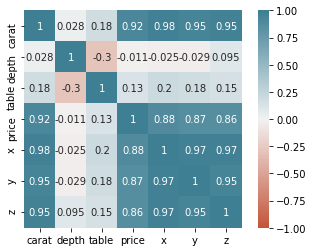

In [54]:
#df.drop('Unnamed: 0',axis = 1, inplace = True)  #  drop unnecessary index.
corr=data.corr()
sns.heatmap(corr,vmin=-1, vmax=1, center=0,
    cmap=sns.diverging_palette(20, 220, n=200),
    square=True, annot = True
)
#Correlation table of numerical features.
#Strong correlation between carat and price draws attention .

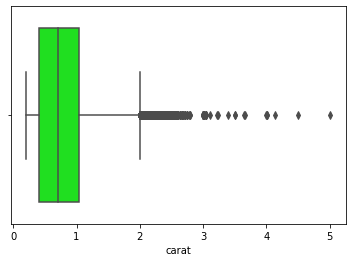

In [55]:
sns.boxplot(x="carat",data=data,color ="lime"); # box plot of carat feature. There are a lot of outliers.

/usr/local/lib/python3.7/dist-packages/seaborn/distributions.py:2557: FutureWarning:

`distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).



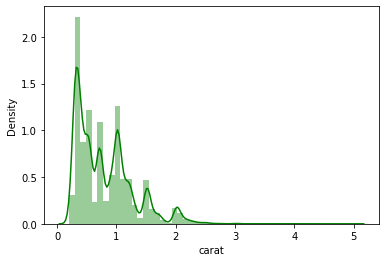

In [56]:
sns.distplot(data.carat, hist=True, kde=True,color = "green") #distribution plot of carat feature.
#The distribution is left skewed due to outliers.

/usr/local/lib/python3.7/dist-packages/seaborn/distributions.py:2557: FutureWarning:

`distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).



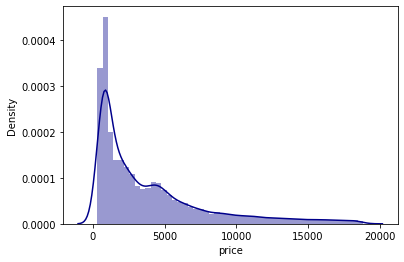

In [61]:
sns.distplot(data.price, hist=True, kde=True,color = "darkblue");

In [62]:
data.cut.unique()
# quality of the cut (Fair, Good, Very Good, Premium, Ideal) ordinal variable.

array(['Ideal', 'Premium', 'Good', 'Very Good', 'Fair'], dtype=object)

In [63]:
data.cut.value_counts() # count values of cut types.

Ideal        21551
Premium      13791
Very Good    12082
Good          4906
Fair          1610
Name: cut, dtype: int64

/usr/local/lib/python3.7/dist-packages/seaborn/categorical.py:3714: UserWarning:

The `factorplot` function has been renamed to `catplot`. The original name will be removed in a future release. Please update your code. Note that the default `kind` in `factorplot` (`'point'`) has changed `'strip'` in `catplot`.



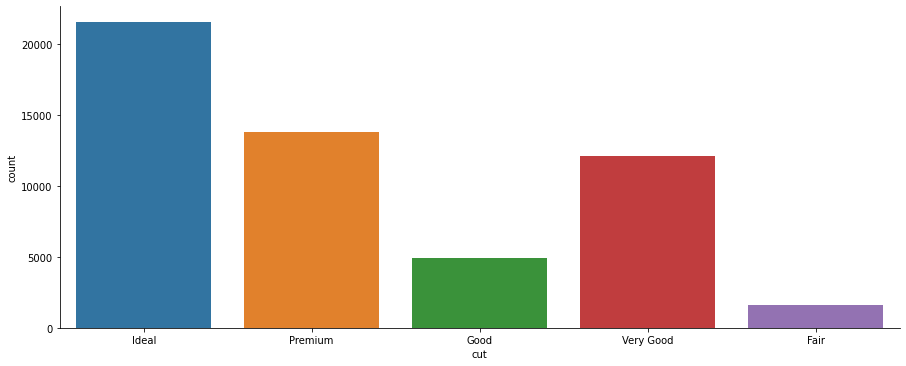

In [64]:
sns.factorplot(x='cut', data=data , kind='count',aspect=2.5 ) # bar plot of cut feature count.
#most of diamonds that in the data is ideal cut.

In [66]:
data.color.unique()
# there are 7 different color of diamonds in the data.

array(['E', 'I', 'J', 'H', 'F', 'G', 'D'], dtype=object)

/usr/local/lib/python3.7/dist-packages/seaborn/categorical.py:3714: UserWarning:

The `factorplot` function has been renamed to `catplot`. The original name will be removed in a future release. Please update your code. Note that the default `kind` in `factorplot` (`'point'`) has changed `'strip'` in `catplot`.



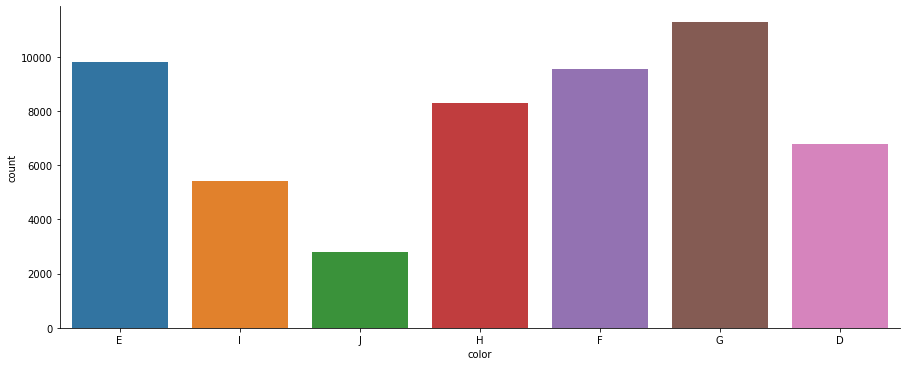

In [67]:
sns.factorplot(x='color', data=data , kind='count',aspect=2.5 )
#barplot of diamond colors. 

In [68]:
data.groupby('color').carat.mean()
  #grouping diamonds according to their colors then looking their carat means.

color
D    0.657795
E    0.657867
F    0.736538
G    0.771190
H    0.911799
I    1.026927
J    1.162137
Name: carat, dtype: float64

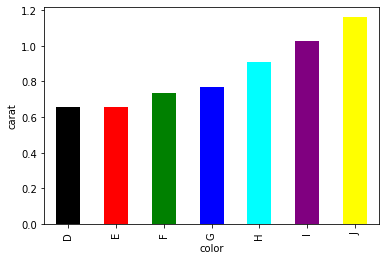

In [69]:
data.groupby('color').carat.mean().plot(kind = 'bar', 
                                      color=['black', 'red', 'green', 'blue', 'cyan','purple','yellow'],
                                      xlabel = 'color',
                                      ylabel="carat")
#color diamond from  D (best) to J (worst) 
#bar plot of the carat means with respect to colors.

In [70]:
CutPrice = data.groupby('cut').price.mean()
CutPrice

cut
Fair         4358.757764
Good         3928.864452
Ideal        3457.541970
Premium      4584.257704
Very Good    3981.759891
Name: price, dtype: float64

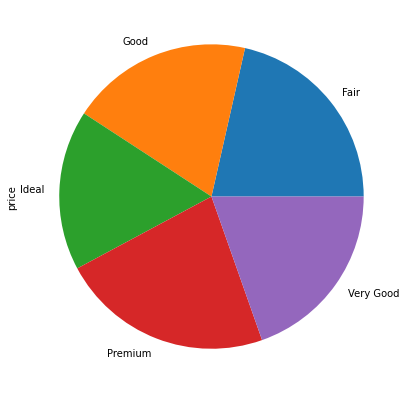

In [71]:
CutPrice.plot(kind='pie',figsize=(7,7))
#pie plot of mean prices of cut types

Outlier Elemination

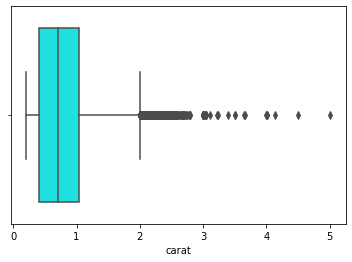

In [75]:
sns.boxplot(x="carat",data=data,color ="cyan")

/usr/local/lib/python3.7/dist-packages/seaborn/_decorators.py:43: FutureWarning:

Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.



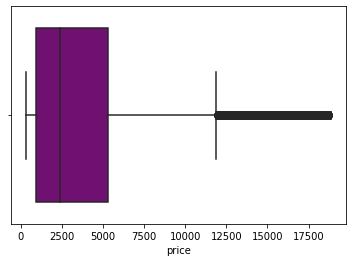

In [72]:
sns.boxplot(data.price,color ="purple")
#outliers of price column starts from 13000.

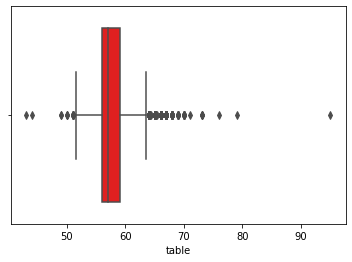

In [74]:
sns.boxplot(x="table",data=data,color ="red")
#outlier observation of table feature

In [76]:
df=data.copy()

In [77]:
#appyling outlier elemination by filtering data points
df = df[(df["price"]< 14500)]
df = df[(df["carat"]< 3)]
df = df[(df["table"]< 64)&(df["table"]>50)]

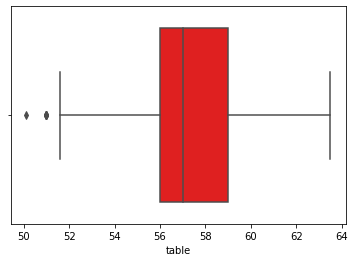

In [78]:
sns.boxplot(x="table",data=df,color ="red") # box plot of table column after outlier elemination


In [79]:
df.shape 


(51470, 10)

## Prediction

we saw that the predictions for the entire data set  𝕐̂
Y
^
  can be computed as:
𝕐̂=𝕏𝜃
Y
^
=
X
θ
 
The covariate matrix  𝕏∈ℝ𝑛,𝑑+1
X
∈
R
n
,
d
+
1
  has  𝑛
n
  rows corresponding to each record in the dataset and  𝑑+1
d
+
1
  columns corresponding to the original  𝑑
d
  columns in the data plus an additional 1s column vector. For example, the first five rows of  𝕏
X
  for this dataset would look like:

In [17]:
n,d = data[['carat', 'depth', 'table']].shape
print("n = ", n)
print("d = ", d)

n =  53940
d =  3


The following function attaches 1s to each of the rows in the matrix. Here I am using the np.hstack function to add an extra column.

In [18]:
def add_ones_column(data):
    return np.hstack([np.ones((n,1)), data])

In [19]:
X = add_ones_column(data[['carat', 'depth', 'table']].to_numpy())
X

array([[ 1.  ,  0.23, 61.5 , 55.  ],
       [ 1.  ,  0.21, 59.8 , 61.  ],
       [ 1.  ,  0.23, 56.9 , 65.  ],
       ...,
       [ 1.  ,  0.7 , 62.8 , 60.  ],
       [ 1.  ,  0.86, 61.  , 58.  ],
       [ 1.  ,  0.75, 62.2 , 55.  ]])

We can define the linear model in python using numpy. Here we assume the input is in row vector form so this function will work with a single row or the entire matrix. Note a single row is stored in column vector form (as this is the case in most math textbooks).

The @ symbol is the matrix multiply operation and is equivalent to writing xt.dot(theta).

In [20]:
def linear_model(theta, xt): 
    return xt @ theta # The @ symbol is matrix multiply

we used np.random.randn, which generates draws from a normal (Gaussian) distribution with mean 0 and variance 1 (the parameters d+1 and 1 specify the number of rows and columns that the returning array should have). The fact that these values are drawn from a normal distribution are irrelevant here, just think of them as coming from a random number generator.

In [21]:
np.random.seed(42)
theta_guess = np.random.randn(d+1, 1)
theta_guess

array([[ 0.49671415],
       [-0.1382643 ],
       [ 0.64768854],
       [ 1.52302986]])

In [22]:
#Making a single prection for the 3rd row:
linear_model(theta_guess, X[2,:])

array([136.31533185])

In [23]:
#Making a prediction for all the rows at once:
linear_model(theta_guess, X)

array([[124.06440056],
       [132.10427447],
       [136.31533185],
       ...,
       [132.45656072],
       [128.22253935],
       [124.4458851 ]])

In [24]:
Y_hat = X @ theta_guess #math form, result is the same
Y_hat

array([[124.06440056],
       [132.10427447],
       [136.31533185],
       ...,
       [132.45656072],
       [128.22253935],
       [124.4458851 ]])

## Defining and Minimizing the Loss

In order to calculate the loss we need the response vector  𝕐
Y
  (the thing we are trying to predict).

In [25]:
Y =  data[['price']].to_numpy()
Y

array([[ 326],
       [ 326],
       [ 327],
       ...,
       [2757],
       [2757],
       [2757]])

In [26]:
#Directly writing the average squared loss:
def squared_loss(theta):
    return np.mean((Y - X @ theta)**2)

In [27]:
squared_loss(theta_guess)

30389793.20618836

Using matrix notation:

In [28]:
def squared_loss(theta):
    return ((Y - X @ theta).T @ (Y - X @ theta)).item() / Y.shape[0]

In [29]:
Y.shape[0]

53940

In [30]:
squared_loss(theta_guess)

30389793.206188362

we defined the normal equation as:

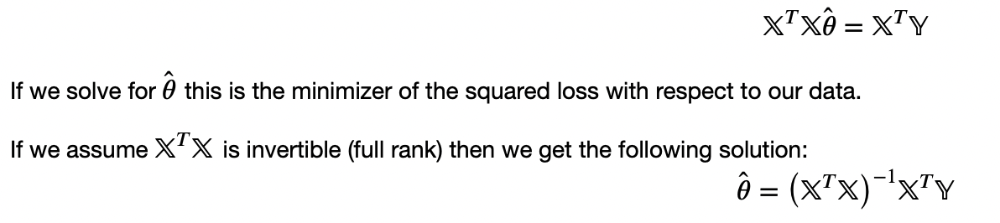

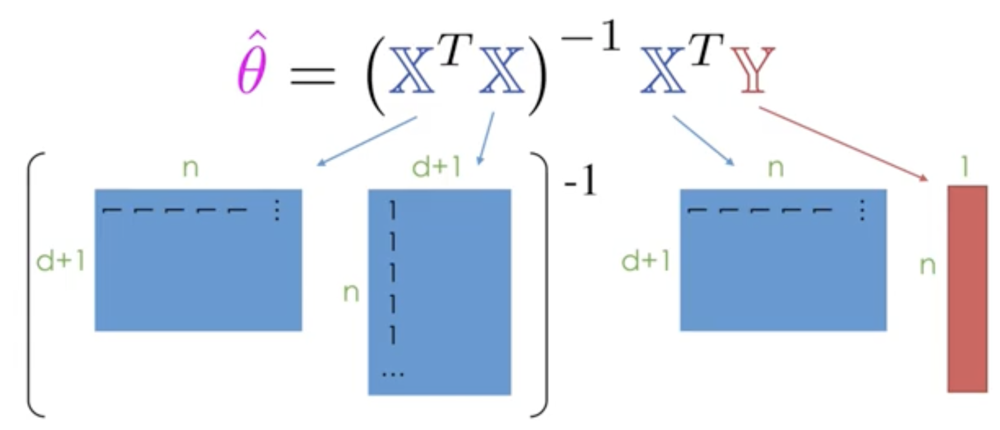

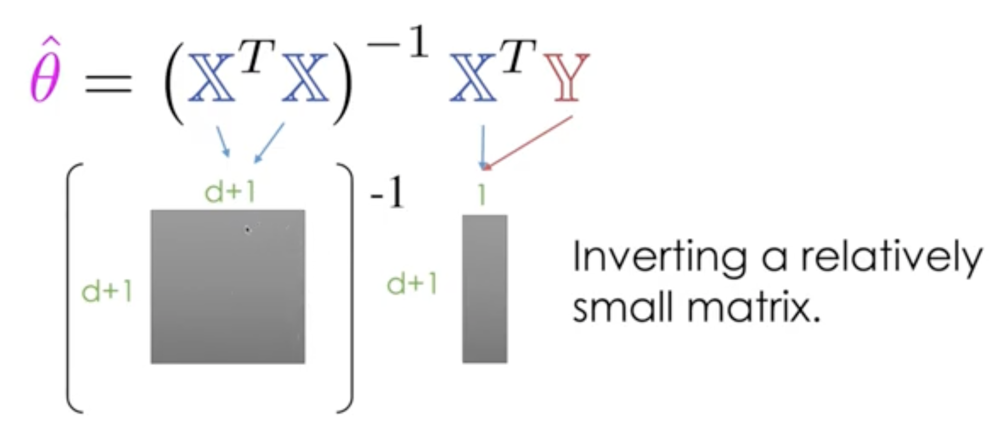

While it is not as numerically stable or efficient. We can compute  𝜃̂
θ
^
  by direction using matrix inversion. To do this, we import the inv function for the numpy linear algebra library:

In [31]:
from numpy.linalg import inv

In [32]:
theta_hat = inv(X.T @ X) @ X.T @ Y
theta_hat

array([[13003.44052424],
       [ 7858.77050994],
       [ -151.23634689],
       [ -104.47278016]])

A more efficient way to solve the normal equations is using the solve function to solve the linear systems:
𝐴𝜃=𝑏
A
θ
=
b
 
where  𝐴=𝕏𝑇𝕏
A
=
X
T
X
  and  𝑏=𝕏𝑇𝕐
b
=
X
T
Y
 . The solve function can be implement slightly more efficiently by avoiding the inversion and subsequent matrix multiply. For matrices which are less well behaved, solve can also be more numerically stable.

In [33]:
from numpy.linalg import solve
theta_hat = solve(X.T @ X, X.T @ Y)
theta_hat

array([[13003.44052424],
       [ 7858.77050994],
       [ -151.23634689],
       [ -104.47278016]])

We have just computed the global optimum of the squared loss.

Now that we have estimated the model parameters  𝜃̂
θ
^
  we can now also predict the price  𝕐̂
Y
^
  for each of our diamonds

In [34]:
Y_hat = X @ theta_hat

In [35]:
Y_hat

array([[-236.0805007 ],
       [-762.99080215],
       [-585.12110662],
       ...,
       [2738.57048722],
       [4477.14475352],
       [3744.61472164]])

In [36]:
import plotly.express as px

In [37]:
fig = px.scatter(x = X[:,1], y = Y - Y_hat,opacity=0.2)
fig.update_xaxes(title="Carat")
fig.update_yaxes(title="Residual")
fig

In [38]:
fig = px.scatter(x = X[:,2], y = Y - Y_hat,opacity=0.2)
fig.update_xaxes(title="Depth")
fig.update_yaxes(title="Residual")
fig

In [39]:
fig = px.scatter(x = X[:,3], y = Y - Y_hat,opacity=0.2)
fig.update_xaxes(title="Table")
fig.update_yaxes(title="Residual")
fig

A better way to visualize higher dimensional regression models is to compare the Predicted Value against the Observed value

In [41]:
import plotly.graph_objects as go

In [42]:
fig = px.scatter(x = Y.flatten(), y = Y_hat.flatten(), opacity=0.2)
fig.add_trace(go.Scatter(x=[0,20000], y=[0, 20000], name="Y_hat=Y"))
fig.update_xaxes(title="Y")
fig.update_yaxes(title="Y_hat")
fig

ref: https://ds100.org/sp20/resources/assets/lectures/lec15/LeastSquaresLinearRegression.html

## 2D data sample

In [80]:
df

,carat,cut,color,clarity,depth,table,price,x,y,z
1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
6,0.24,Very Good,J,VVS2,62.8,57.0,336,3.94,3.96,2.48
...,...,...,...,...,...,...,...,...,...,...
53936,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53937,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53938,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53939,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


In [81]:
subdata=df[['carat', 'depth', 'table']].copy()
subdata.head()

,carat,depth,table
1,0.23,61.5,55.0
2,0.21,59.8,61.0
4,0.29,62.4,58.0
5,0.31,63.3,58.0
6,0.24,62.8,57.0


In [82]:
X1=subdata["depth"]
X2=subdata["table"]
Y=subdata["carat"]

In [83]:
fig = go.Figure()
data_scatter = go.Scatter3d(x=X2, y=X1, z=Y, 
                            mode="markers",
                            marker=dict(size=2))
fig.add_trace(data_scatter)
fig.update_layout(margin=dict(l=0, r=0, t=0, b=0), 
                  height=600)
fig

In [84]:
def add_ones_column(X):
    return np.hstack([np.ones((X.shape[0],1)), X])

In [86]:
subdata

,carat,depth,table
1,0.23,61.5,55.0
2,0.21,59.8,61.0
4,0.29,62.4,58.0
5,0.31,63.3,58.0
6,0.24,62.8,57.0
...,...,...,...
53936,0.72,60.8,57.0
53937,0.72,63.1,55.0
53938,0.70,62.8,60.0
53939,0.86,61.0,58.0


In [87]:
X=subdata[["depth","table"]]
add_ones_column(X)

array([[ 1. , 61.5, 55. ],
       [ 1. , 59.8, 61. ],
       [ 1. , 62.4, 58. ],
       ...,
       [ 1. , 62.8, 60. ],
       [ 1. , 61. , 58. ],
       [ 1. , 62.2, 55. ]])

In [88]:
X.head()

,depth,table
1,61.5,55.0
2,59.8,61.0
4,62.4,58.0
5,63.3,58.0
6,62.8,57.0


In [90]:
from numpy.linalg import inv, solve
def least_squares_by_solve(X, Y):
    return solve(X.T @ X, X.T @ Y)

def least_squares_by_inv(X, Y):
    return inv(X.T @ X) @ X.T @ Y

In [92]:
theta_hat = least_squares_by_solve(add_ones_column(X), Y)

In [93]:
theta_hat

array([-3.622429  ,  0.031078  ,  0.04282672])

In [94]:
def model_append_ones(X):
    return add_ones_column(X) @ theta_hat

In [103]:
Y_hat=model_append_ones(X)
Y_hat

array([0.64433777, 0.84846552, 0.80078815, ..., 0.89887279, 0.75727895,
       0.66609237])

In [114]:
Y_hat

array([0.64433777, 0.84846552, 0.80078815, ..., 0.89887279, 0.75727895,
       0.66609237])

In [116]:
Y

1        0.23
2        0.21
4        0.29
5        0.31
6        0.24
         ... 
53936    0.72
53937    0.72
53938    0.70
53939    0.86
53940    0.75
Name: carat, Length: 51470, dtype: float64

In [115]:
Y.values

array([0.23, 0.21, 0.29, ..., 0.7 , 0.86, 0.75])

In [118]:
fig = px.scatter(x = Y.values.flatten(), y = Y_hat.flatten(), opacity=0.2)
fig.update_xaxes(title="Y")
fig.update_yaxes(title="Y_hat")
fig

# Simple Sklearn start

Scikit Learn, or call it sklearn (pronounced s-k-learn), is an large package of useful machine learning algorithms. For this lecture, we will use the LinearRegression model in the linear_model module. What you should know about sklearn models:

Models are created by first building an instance of the model:
model = ModelType(args)

You then fit the model by calling the fit function passing in data:
model.fit(df[['X1' 'X1']], df[['Y']])

You then can make predictions by calling predict:
model.predict(df2[['X1' 'X1']])

The neat part about sklearn is most models behave like this. So if you want to try a cool new model you just change the class of mode you are using.

## Simulation Data

We will generate a one-dimensional dataset with a simple model (including some noise), and we will try to fit a function to this data. With this function, we can predict values on new data points. This is a curve fitting regression problem.

In [ ]:
import numpy as np
import scipy.stats as st
import sklearn.linear_model as lm
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
#define a deterministic nonlinear function underlying our generative model:
def f(x):
    return np.exp(3 * x)

In [ ]:
#generate the values along the curve on [0,2].
x_tr = np.linspace(0., 2, 200)
y_tr = f(x_tr)

In [ ]:
# let's generate data points within [0,1]. We use the function f and we add some Gaussian noise.
x = np.array([0, .1, .2, .5, .8, .9, 1])
y = f(x) + 3 * np.random.randn(len(x))

Text(0.5, 1.0, 'Generative model')

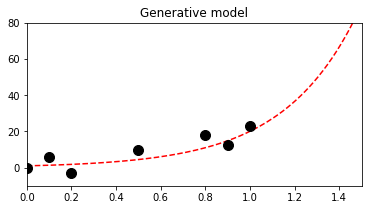

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(6, 3))
ax.plot(x_tr, y_tr, '--r')
ax.plot(x, y, 'ok', ms=10)
ax.set_xlim(0, 1.5)
ax.set_ylim(-10, 80)
ax.set_title('Generative model')

### Linear Regression

In [ ]:
y.shape

(7,)

In [ ]:
newx=x[:, np.newaxis]#add one dimention
newx.shape

(7, 1)

We use scikit-learn to fit a linear model to the data. There are three steps. First, we create the model (an instance of the LinearRegression class). Then, we fit the model to our data. Finally, we predict values from our trained model.

In [ ]:
# We create the model.
lr = lm.LinearRegression()
# We train the model on our training dataset.
lr.fit(newx, y)
# Now, we predict points with our trained model.
newxr=x_tr[:, np.newaxis]
y_lr = lr.predict(newxr)
#We need to convert x and x_tr to column vectors, as it is a general convention in scikit-learn that observations are rows, while features are columns. Here, we have seven observations with one feature.

In [ ]:
print(lr.coef_) 

[20.694996]


In [ ]:
y_lr.shape

(200,)

In [ ]:
r2 = round(lr.score(newx, y),2)
print(r2)

0.81


Text(0.5, 1.0, 'Linear regression')

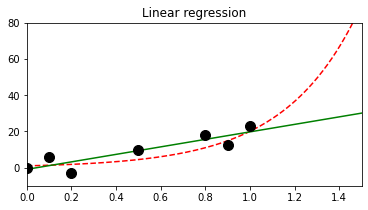

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(6, 3))
ax.plot(x_tr, y_tr, '--r')
ax.plot(x_tr, y_lr, 'g')
ax.plot(x, y, 'ok', ms=10)
ax.set_xlim(0, 1.5)
ax.set_ylim(-10, 80)
ax.set_title("Linear regression")

In [ ]:
y_pred = lr.predict(x[:, np.newaxis])
y_pred.shape

(7,)

In [ ]:
np.mean((y_pred - y)**2)# mean square error

14.648224494403584

In [ ]:
fig.savefig("linearregression1.pdf")

In [ ]:
from sklearn.metrics import mean_squared_error

mse = (mean_squared_error(y, y_pred))
r2 = round(lr.score(newx, y),2)

print("The model performance for training set:")
print('MSE is {}'.format(mse))
print('R2 score is {}'.format(r2))

The model performance for training set:
MSE is 14.648224494403584
R2 score is 0.81


### Polynomial Regression

we will fit a polynomial function to our data points. We can still use linear regression for this, by precomputing the exponents of our data points. This is done by generating a Vandermonde matrix, using the np.vander() function. 

In [ ]:
x

array([0. , 0.1, 0.2, 0.5, 0.8, 0.9, 1. ])

In [ ]:
np.vander(x, 2 + 1) #https://numpy.org/doc/1.18/reference/generated/numpy.vander.html, https://en.wikipedia.org/wiki/Vandermonde_matrix
# the i-th output column is the input vector raised element-wise to the power of N - i - 1

array([[0.  , 0.  , 1.  ],
       [0.01, 0.1 , 1.  ],
       [0.04, 0.2 , 1.  ],
       [0.25, 0.5 , 1.  ],
       [0.64, 0.8 , 1.  ],
       [0.81, 0.9 , 1.  ],
       [1.  , 1.  , 1.  ]])

Coefficients, degree 2:
	 9.99 10.71 0.00
MSE:  13.942405428013288
MSE2:  13.942405428013288
R2:  0.82
Coefficients, degree 7:
	 -1892.03 5348.82 -1752.15 -6771.03 7308.32 -2461.28 242.65 0.00
MSE:  3.8811362073834487e-25
MSE2:  3.8811362073834487e-25
R2:  1.0


Text(0.5, 1.0, 'Linear regression')

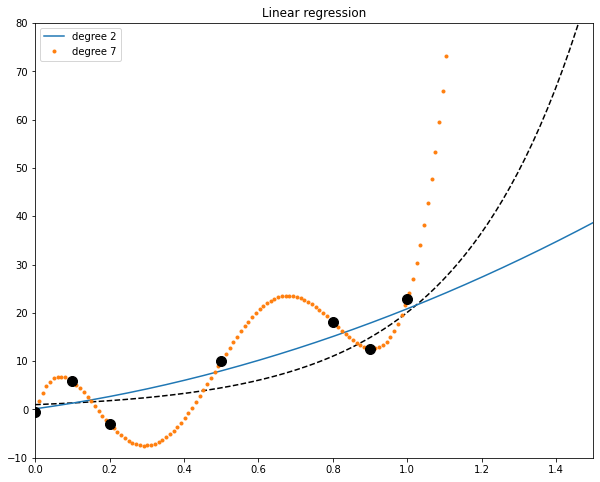

In [ ]:
from sklearn.metrics import mean_squared_error

lrp = lm.LinearRegression()
fig, ax = plt.subplots(1, 1, figsize=(10, 8))
ax.plot(x_tr, y_tr, '--k')

#draw two cases: degree=2, degree=7
for deg, s in zip([2, 7], ['-', '.']):
    x_train=np.vander(x, deg + 1)
    lrp.fit(x_train, y)
    y_lrp = lrp.predict(np.vander(x_tr, deg + 1))
    ax.plot(x_tr, y_lrp, s,
            label=f'degree {deg}')
    ax.legend(loc=2)
    ax.set_xlim(0, 1.5)
    ax.set_ylim(-10, 80)
    # Print the model's coefficients.
    print(f'Coefficients, degree {deg}:\n\t',
          ' '.join(f'{c:.2f}' for c in lrp.coef_))
    y_pred = lrp.predict(x_train)
    #print(y_pred)
    mse=np.mean((y_pred - y)**2)# mean square error
    mse2 = (mean_squared_error(y, y_pred))
    r2 = round(lrp.score(x_train, y),2)
    print("MSE: ", mse)
    print("MSE2: ", mse2)
    print("R2: ", r2)
ax.plot(x, y, 'ok', ms=10)
ax.set_title("Linear regression")

The high degree polynomial seems really bad at predicting values outside the data points (look for example at the x≥1 portion). This is what we call overfitting; by using a too-complex model, we obtain a better fit on the trained dataset, but a less robust model outside this set.

### Ridge and Lasso regression
It works like linear regression except that it prevents the polynomial's coefficients from becoming too big. By adding a regularization term in the loss function, ridge regression imposes some structure on the underlying model. 

bias/variance tradeoff: the larger the ridge alpha parameter, the higher the bias and the lower the variance.
The bias introduced by the ridge regression is called a regularization.

Coefficients, degree 2: 9.88 9.83 0.00
MSE:  14.080527262013716
MSE2:  14.080527262013716
R2:  0.81
Coefficients, degree 7: 1.55 1.71 1.95 2.30 2.83 3.54 4.15 0.00
MSE:  17.904034914469033
MSE2:  17.904034914469033
R2:  0.76


Text(0.5, 1.0, 'Ridge regression')

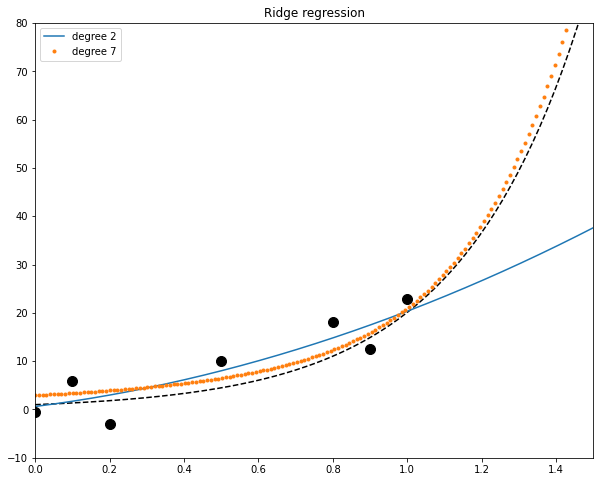

In [ ]:
#ridge = lm.Ridge(alpha=.5)
ridge = lm.RidgeCV() #scikit-learn provides another model called RidgeCV, which includes a parameter search with cross-validation. In practice, this means that we don't have to tweak this parameter by hand

fig, ax = plt.subplots(1, 1, figsize=(10, 8))
ax.plot(x_tr, y_tr, '--k')

for deg, s in zip([2, 7], ['-', '.']):
    x_train=np.vander(x, deg + 1)
    ridge.fit(x_train, y)
    y_ridge = ridge.predict(np.vander(x_tr, deg + 1))
    ax.plot(x_tr, y_ridge, s,
            label='degree ' + str(deg))
    ax.legend(loc=2)
    ax.set_xlim(0, 1.5)
    ax.set_ylim(-10, 80)
    # Print the model's coefficients.
    print(f'Coefficients, degree {deg}:',
          ' '.join(f'{c:.2f}' for c in ridge.coef_))
    y_pred = ridge.predict(x_train)
    #print(y_pred)
    mse=np.mean((y_pred - y)**2)# mean square error
    mse2 = (mean_squared_error(y, y_pred))
    r2 = round(ridge.score(x_train, y),2)
    print("MSE: ", mse)
    print("MSE2: ", mse2)
    print("R2: ", r2)

ax.plot(x, y, 'ok', ms=10)
ax.set_title("Ridge regression")

Coefficients, degree 2: 10.01 9.99 0.00
MSE:  14.012408135654425
MSE2:  14.012408135654425
R2:  0.82
Coefficients, degree 7: 0.00 0.00 0.00 0.00 0.00 10.01 9.99 0.00
MSE:  14.01240816769045
MSE2:  14.01240816769045
R2:  0.82


Text(0.5, 1.0, 'Lasso regression')

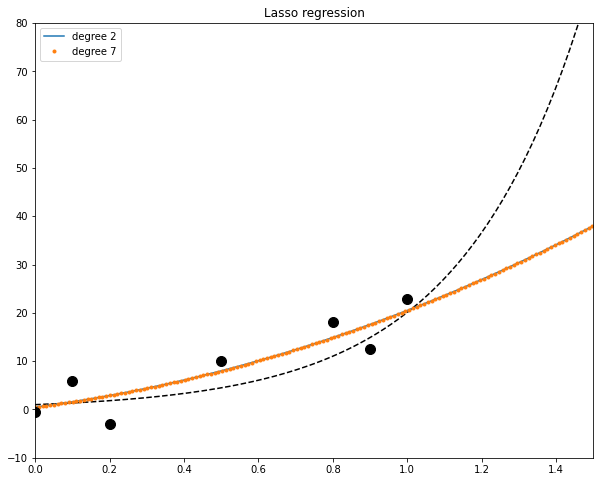

In [ ]:
regr = lm.Lasso(alpha=0.1)
#regr = lm.LassoCV()

fig, ax = plt.subplots(1, 1, figsize=(10, 8))
ax.plot(x_tr, y_tr, '--k')

for deg, s in zip([2, 7], ['-', '.']):
    x_train=np.vander(x, deg + 1)
    regr.fit(x_train, y)
    y_lasso = regr.predict(np.vander(x_tr, deg + 1))
    ax.plot(x_tr, y_lasso, s,
            label='degree ' + str(deg))
    ax.legend(loc=2)
    ax.set_xlim(0, 1.5)
    ax.set_ylim(-10, 80)
    # Print the model's coefficients.
    print(f'Coefficients, degree {deg}:',
          ' '.join(f'{c:.2f}' for c in regr.coef_))
    y_pred = regr.predict(x_train)
    #print(y_pred)
    mse=np.mean((y_pred - y)**2)# mean square error
    mse2 = (mean_squared_error(y, y_pred))
    r2 = round(regr.score(x_train, y),2)
    print("MSE: ", mse)
    print("MSE2: ", mse2)
    print("R2: ", r2)

ax.plot(x, y, 'ok', ms=10)
ax.set_title("Lasso regression")

## Diamond dataset

In [120]:
import numpy as np
import pandas as pd

diamond = pd.read_csv("diamonds.csv", index_col=0)
diamond.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


### Categorical Feature Encoding

In [121]:
# We will use labelencoding to encode out categorical features.
from sklearn import preprocessing

label_cut = preprocessing.LabelEncoder()
label_color = preprocessing.LabelEncoder()
label_clarity = preprocessing.LabelEncoder()


diamond['cut'] = label_cut.fit_transform(diamond['cut'])
diamond['color'] = label_color.fit_transform(diamond['color'])
diamond['clarity'] = label_clarity.fit_transform(diamond['clarity'])

In [123]:
diamond

,carat,cut,color,clarity,depth,table,price,x,y,z
1,0.23,2,1,3,61.5,55.0,326,3.95,3.98,2.43
2,0.21,3,1,2,59.8,61.0,326,3.89,3.84,2.31
3,0.23,1,1,4,56.9,65.0,327,4.05,4.07,2.31
4,0.29,3,5,5,62.4,58.0,334,4.20,4.23,2.63
5,0.31,1,6,3,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53936,0.72,2,0,2,60.8,57.0,2757,5.75,5.76,3.50
53937,0.72,1,0,2,63.1,55.0,2757,5.69,5.75,3.61
53938,0.70,4,0,2,62.8,60.0,2757,5.66,5.68,3.56
53939,0.86,3,4,3,61.0,58.0,2757,6.15,6.12,3.74


### Linear Regression

In [142]:
y = diamond['price']  #target variable

# features = ['carat', 'cut', 'color', 'clarity',
#             'depth', 'table', 'price']  #predictor variables
features = ['carat', 'cut', 'color', 'clarity',
            'depth', 'table']  #predictor variables

X = diamond[features]

In [143]:
X

,carat,cut,color,clarity,depth,table
1,0.23,2,1,3,61.5,55.0
2,0.21,3,1,2,59.8,61.0
3,0.23,1,1,4,56.9,65.0
4,0.29,3,5,5,62.4,58.0
5,0.31,1,6,3,63.3,58.0
...,...,...,...,...,...,...
53936,0.72,2,0,2,60.8,57.0
53937,0.72,1,0,2,63.1,55.0
53938,0.70,4,0,2,62.8,60.0
53939,0.86,3,4,3,61.0,58.0


In [144]:
from sklearn.model_selection import train_test_split
train_X, val_X, train_y, val_y = train_test_split(X, y, test_size=0.3, random_state=2021)

In [145]:
from sklearn.preprocessing import StandardScaler
from sklearn import metrics
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline

pipeLR= Pipeline([("std_scalar1",StandardScaler()),
                     ("lr_regressor",LinearRegression())])

In [146]:
pipeLR.fit(train_X, train_y)

Pipeline(memory=None,
         steps=[('std_scalar1',
                 StandardScaler(copy=True, with_mean=True, with_std=True)),
                ('lr_regressor',
                 LinearRegression(copy_X=True, fit_intercept=True, n_jobs=None,
                                  normalize=False))],
         verbose=False)

In [147]:
pipeLR.score(train_X, train_y)

0.8801284386312537

In [148]:
cv_score = cross_val_score(pipeLR,train_X, train_y,scoring="neg_mean_squared_error", cv=10)

In [149]:
cv_score

array([-1761410.88106742, -1895666.35842435, -2151743.02550259,
       -2070194.93666862, -1984980.34958997, -1861043.65816801,
       -1969834.68950241, -1774328.02465588, -1867835.12593713,
       -1929880.37637106])

In [150]:
cv_score.mean()

-1926691.742588744

In [151]:
pred = pipeLR.predict(val_X)

In [152]:
# Model Evaluation with different error metrics
print("R^2:",metrics.r2_score(val_y, pred))
print("Adjusted R^2:",1 - (1-metrics.r2_score(val_y, pred))*(len(val_y)-1)/(len(val_y)-val_X.shape[1]-1))
print("MAE:",metrics.mean_absolute_error(val_y, pred))
print("MSE:",metrics.mean_squared_error(val_y, pred))
print("RMSE:",np.sqrt(metrics.mean_squared_error(val_y, pred)))

R^2: 0.8808017286014875
Adjusted R^2: 0.8807575128593923
MAE: 921.675482348783
MSE: 1855845.7445393538
RMSE: 1362.294294394333


In [160]:
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso

In [161]:
l1_model = Ridge(alpha=1)
l2_model = Lasso(alpha=1)

In [162]:
l1_model.fit(train_X, train_y)
l2_model.fit(train_X, train_y)

Lasso(alpha=1, copy_X=True, fit_intercept=True, max_iter=1000, normalize=False,
      positive=False, precompute=False, random_state=None, selection='cyclic',
      tol=0.0001, warm_start=False)

In [164]:
print(f"Ridge Regression : {l1_model.score(train_X, train_y)}")
print(f"Lasso regression: {l2_model.score(train_X, train_y)}")

Ridge Regression : 0.880128422507571
Lasso regression: 0.880127851125122


### Other Regressors

In [153]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
#from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor

In [154]:
pipeDT= Pipeline([("std_scalar2",StandardScaler()),
                     ("dt_regressor",DecisionTreeRegressor())])

pipeRF= Pipeline([("std_scalar3",StandardScaler()),
                     ("rf_regressor",RandomForestRegressor())])

pipeXGB= Pipeline([("std_scalar4",StandardScaler()),
                     ("XGB_regressorr",XGBRegressor())])

In [155]:
# List of all the pipelines
pipelines = [pipeLR, pipeDT, pipeRF, pipeXGB]


pipe_dict = {0: "LinearRegression", 1: "DecisionTree", 2: "RandomForest", 3: "XGBRegressor"}


# Fit the pipelines
for pipe in pipelines:
    pipe.fit(train_X, train_y)

[20:36:35] WARNING: /workspace/src/objective/regression_obj.cu:152: reg:linear is now deprecated in favor of reg:squarederror.


In [156]:
cv_results_NMSE = []
for i, model in enumerate(pipelines):
    cv_score = cross_val_score(model,train_X, train_y,scoring="neg_mean_squared_error", cv=10)
    cv_results_NMSE.append(cv_score)
    print("%s: %f " % (pipe_dict[i], cv_score.mean()))

LinearRegression: -1926691.742589 
DecisionTree: -538478.018825 
RandomForest: -316020.945214 
[20:38:14] WARNING: /workspace/src/objective/regression_obj.cu:152: reg:linear is now deprecated in favor of reg:squarederror.
[20:38:15] WARNING: /workspace/src/objective/regression_obj.cu:152: reg:linear is now deprecated in favor of reg:squarederror.
[20:38:16] WARNING: /workspace/src/objective/regression_obj.cu:152: reg:linear is now deprecated in favor of reg:squarederror.
[20:38:17] WARNING: /workspace/src/objective/regression_obj.cu:152: reg:linear is now deprecated in favor of reg:squarederror.
[20:38:19] WARNING: /workspace/src/objective/regression_obj.cu:152: reg:linear is now deprecated in favor of reg:squarederror.
[20:38:20] WARNING: /workspace/src/objective/regression_obj.cu:152: reg:linear is now deprecated in favor of reg:squarederror.
[20:38:21] WARNING: /workspace/src/objective/regression_obj.cu:152: reg:linear is now deprecated in favor of reg:squarederror.
[20:38:22] WARNI

negative root mean square error of linear regression and decision tree regressors are very low. This points to overfitting. 

In [157]:
# XGB Model predictions on validation data.
pred = pipeXGB.predict(val_X)

In [158]:
# Model Evaluation with different error metrics
print("R^2:",metrics.r2_score(val_y, pred))
print("Adjusted R^2:",1 - (1-metrics.r2_score(val_y, pred))*(len(val_y)-1)/(len(val_y)-val_X.shape[1]-1))
print("MAE:",metrics.mean_absolute_error(val_y, pred))
print("MSE:",metrics.mean_squared_error(val_y, pred))
print("RMSE:",np.sqrt(metrics.mean_squared_error(val_y, pred)))

R^2: 0.9712405881726309
Adjusted R^2: 0.9712299200755079
MAE: 368.7058750769512
MSE: 447766.8294101093
RMSE: 669.1538159572202


In [159]:
pipeXGB.score(train_X, train_y)

0.9724273807771204

## Boston housing dataset

In [ ]:
from	sklearn.datasets import load_boston 
from	sklearn.preprocessing	import scale 
boston	=	load_boston() #Boston	housing	prices, from UCI

In [ ]:
boston #13 feature variables, 506 samples in this dataset

{'DESCR': ".. _boston_dataset:\n\nBoston house prices dataset\n---------------------------\n\n**Data Set Characteristics:**  \n\n    :Number of Instances: 506 \n\n    :Number of Attributes: 13 numeric/categorical predictive. Median Value (attribute 14) is usually the target.\n\n    :Attribute Information (in order):\n        - CRIM     per capita crime rate by town\n        - ZN       proportion of residential land zoned for lots over 25,000 sq.ft.\n        - INDUS    proportion of non-retail business acres per town\n        - CHAS     Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)\n        - NOX      nitric oxides concentration (parts per 10 million)\n        - RM       average number of rooms per dwelling\n        - AGE      proportion of owner-occupied units built prior to 1940\n        - DIS      weighted distances to five Boston employment centres\n        - RAD      index of accessibility to radial highways\n        - TAX      full-value property-tax rate p

In [ ]:
print(boston.keys())

dict_keys(['data', 'target', 'feature_names', 'DESCR', 'filename'])


In [ ]:
print(boston.feature_names)

['CRIM' 'ZN' 'INDUS' 'CHAS' 'NOX' 'RM' 'AGE' 'DIS' 'RAD' 'TAX' 'PTRATIO'
 'B' 'LSTAT']


In [ ]:
print(boston.DESCR) #The details about the features 

.. _boston_dataset:

Boston house prices dataset
---------------------------

**Data Set Characteristics:**  

    :Number of Instances: 506 

    :Number of Attributes: 13 numeric/categorical predictive. Median Value (attribute 14) is usually the target.

    :Attribute Information (in order):
        - CRIM     per capita crime rate by town
        - ZN       proportion of residential land zoned for lots over 25,000 sq.ft.
        - INDUS    proportion of non-retail business acres per town
        - CHAS     Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)
        - NOX      nitric oxides concentration (parts per 10 million)
        - RM       average number of rooms per dwelling
        - AGE      proportion of owner-occupied units built prior to 1940
        - DIS      weighted distances to five Boston employment centres
        - RAD      index of accessibility to radial highways
        - TAX      full-value property-tax rate per $10,000
        - PTRATIO  pu

In [ ]:
!cp /usr/local/lib/python3.6/dist-packages/sklearn/datasets/data/boston_house_prices.csv .

In [ ]:
import pandas as pd

#Create a dataframe
bos = pd.DataFrame(boston.data, columns = boston.feature_names)
bos['PRICE'] = boston.target

bos.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,PRICE
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


In [ ]:
bos.isnull().sum()

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
PRICE      0
dtype: int64

In [ ]:
bos.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,PRICE
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


/usr/local/lib/python3.6/dist-packages/statsmodels/tools/_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


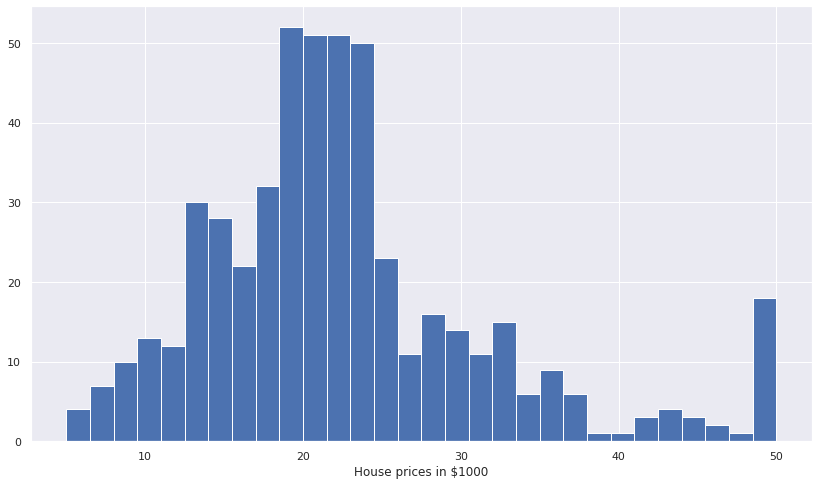

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
#To plot the graph embedded in the notebook
%matplotlib inline

sns.set(rc={'figure.figsize':(14,8)})
plt.hist(bos['PRICE'], bins=30)
plt.xlabel("House prices in $1000")
plt.show()

Create a correlation matrix that measures the linear relationships between the variables. The correlation matrix can be formed by using the corr function from the pandas dataframe library. We will use the heatmap function from the seaborn library to plot the correlation matrix.
The correlation coefficient ranges from -1 to 1. If the value is close to 1, it means that there is a strong positive correlation between the two variables. When it is close to -1, the variables have a strong negative correlation.

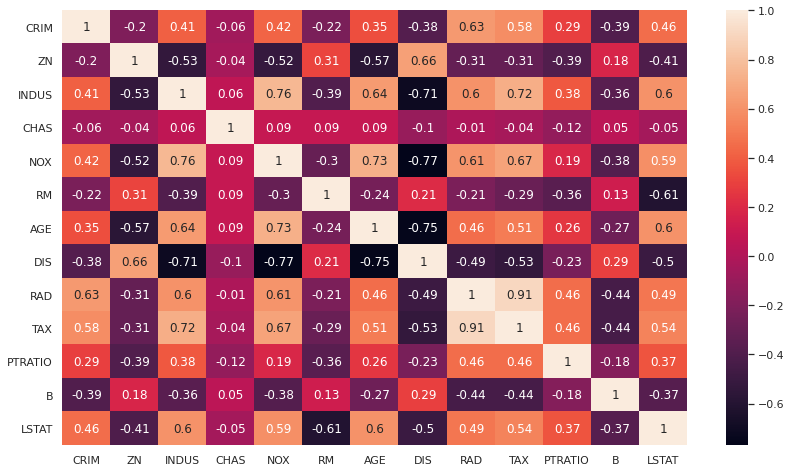

In [ ]:
#Created a dataframe without the price col, since we need to see the correlation between the variables
bos_1 = pd.DataFrame(boston.data, columns = boston.feature_names)

correlation_matrix = bos_1.corr().round(2)
sns.heatmap(data=correlation_matrix, annot=True)

### Linear Regression for one variable

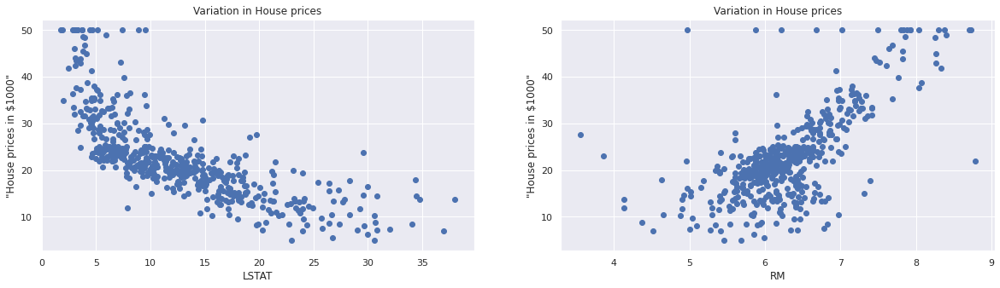

In [ ]:
plt.figure(figsize=(20, 5))

features = ['LSTAT', 'RM']
target = bos['PRICE']

for i, col in enumerate(features):
    plt.subplot(1, len(features) , i+1)
    x = bos[col]
    y = target
    plt.scatter(x, y, marker='o')
    plt.title("Variation in House prices")
    plt.xlabel(col)
    plt.ylabel('"House prices in $1000"')

We will 1st predict the house price with just one variable and then move to the regression with all features

In [ ]:
X_rooms = bos.RM
y_price = bos.PRICE


X_rooms = np.array(X_rooms).reshape(-1,1)
y_price = np.array(y_price).reshape(-1,1)

print(X_rooms.shape)
print(y_price.shape)

(506, 1)
(506, 1)


In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score

#Splitting the data into training and testing sets
X_train_1, X_test_1, Y_train_1, Y_test_1 = train_test_split(X_rooms, y_price, test_size = 0.2, random_state=5)

print(X_train_1.shape)
print(X_test_1.shape)
print(Y_train_1.shape)
print(Y_test_1.shape)

(404, 1)
(102, 1)
(404, 1)
(102, 1)


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

reg_1 = LinearRegression()
reg_1.fit(X_train_1, Y_train_1)

y_train_predict_1 = reg_1.predict(X_train_1)
rmse = (np.sqrt(mean_squared_error(Y_train_1, y_train_predict_1)))
r2 = round(reg_1.score(X_train_1, Y_train_1),2)

print("The model performance for training set:")
print('RMSE is {}'.format(rmse))
print('R2 score is {}'.format(r2))

The model performance for training set:
RMSE is 6.972277149440585
R2 score is 0.43


In [ ]:
# model evaluation for test set

y_pred_1 = reg_1.predict(X_test_1)
rmse = (np.sqrt(mean_squared_error(Y_test_1, y_pred_1)))
r2 = round(reg_1.score(X_test_1, Y_test_1),2)

print("The model performance for training set:")
print("Root Mean Squared Error: {}".format(rmse))
print("R^2: {}".format(r2))

The model performance for training set:
Root Mean Squared Error: 4.895963186952216
R^2: 0.69


(50, 1)


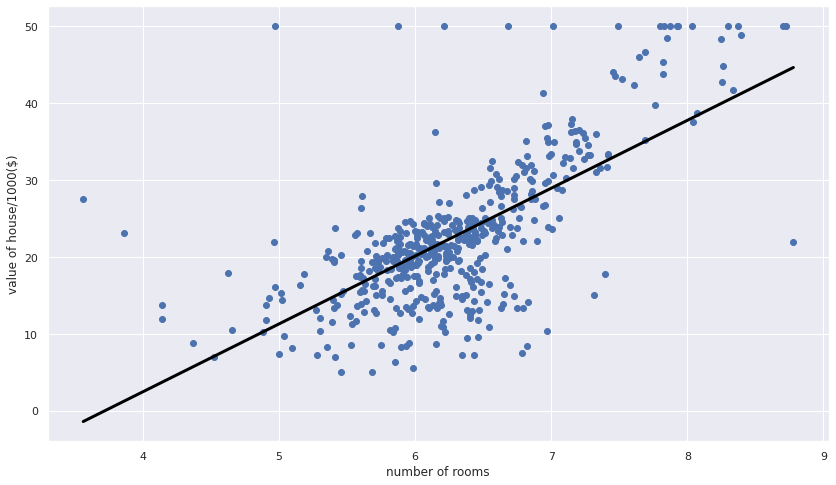

In [ ]:
#Plotting the model fitted line on the output variable
prediction_space = np.linspace(min(X_rooms), max(X_rooms)).reshape(-1,1) 
print(prediction_space.shape)
plt.scatter(X_rooms,y_price)
plt.plot(prediction_space, reg_1.predict(prediction_space), color = 'black', linewidth = 3)
plt.ylabel('value of house/1000($)')
plt.xlabel('number of rooms')
plt.show()

### Regression Model for All the variables

In [ ]:
X = bos.drop('PRICE', axis = 1)
print("X shape: ", X.shape)
y = bos['PRICE']
print("Y shape: ", y.shape)
#alternative way:
# X	=	scale(boston.data) 
# print("X shape: ", X.shape)
# y	=	boston.target 
# print("Y shape: ", y.shape)

X shape:  (506, 13)
Y shape:  (506,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)
print("X_train shape: ", X_train.shape)
print("X_test shape: ", X_test.shape)
print("y_train shape: ", y_train.shape)
print("y_test shape: ", y_test.shape)

X_train shape:  (404, 13)
X_test shape:  (102, 13)
y_train shape:  (404,)
y_test shape:  (102,)


In [ ]:
#reg_all = LinearRegression()
reg_all = LinearRegression(normalize=True)
reg_all.fit(X_train, y_train)

# model evaluation for training set
y_train_predict = reg_all.predict(X_train)
rmse = (np.sqrt(mean_squared_error(y_train, y_train_predict)))
r2 = round(reg_all.score(X_train, y_train),2)

print("The model performance for training set")
print('RMSE is {}'.format(rmse))
print('R2 score is {}'.format(r2))

The model performance for training set
RMSE is 4.6520331848801675
R2 score is 0.75


In [ ]:
# model evaluation for test set

y_pred = reg_all.predict(X_test)
rmse = (np.sqrt(mean_squared_error(y_test, y_pred)))
r2 = round(reg_all.score(X_test, y_test),2) ##use the score method to report the R2 measure

print("The model performance for training set")
print("Root Mean Squared Error: {}".format(rmse))
print("R^2: {}".format(r2))

The model performance for training set
Root Mean Squared Error: 4.928602182665336
R^2: 0.67


Text(0.5, 1.0, 'Actual Prices vs Predicted prices')

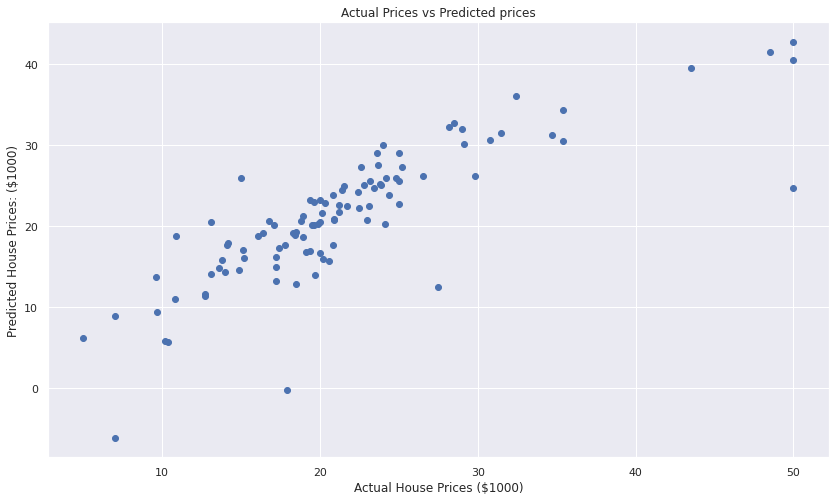

In [ ]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual House Prices ($1000)")
plt.ylabel("Predicted House Prices: ($1000)")
#plt.xticks(range(0, int(max(y_test)),2))
#plt.yticks(range(0, int(max(y_test)),2))
plt.title("Actual Prices vs Predicted prices")

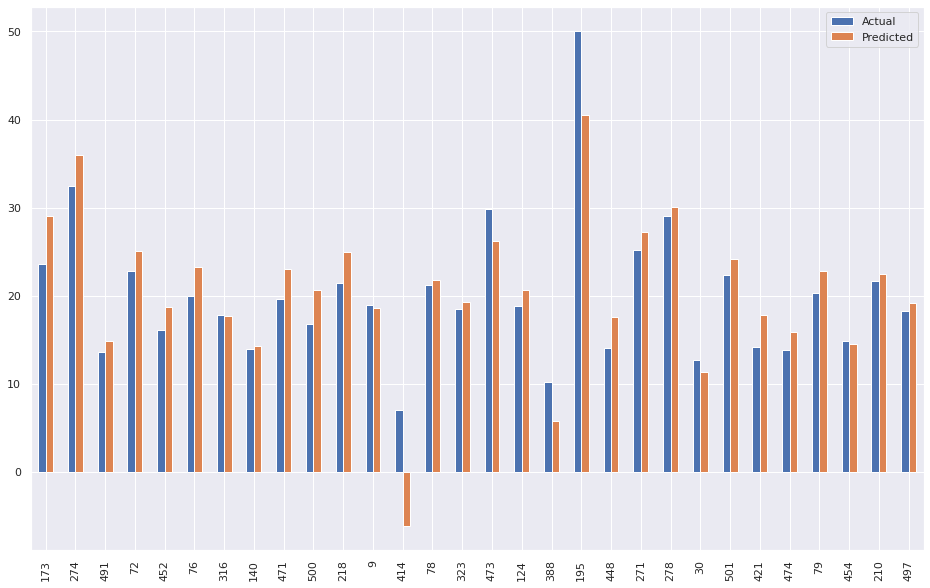

In [ ]:
dfcomp = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
dfcomp1=dfcomp.head(30)
dfcomp1.plot(kind='bar',figsize=(16,10))

In [ ]:
print([a	+	':'	+	str(round(b,	2))	for	a,	b	in zip(boston.feature_names,	reg_all.coef_,)]) 

['CRIM:-0.11', 'ZN:0.03', 'INDUS:0.04', 'CHAS:2.78', 'NOX:-17.2', 'RM:4.44', 'AGE:-0.01', 'DIS:-1.45', 'RAD:0.26', 'TAX:-0.01', 'PTRATIO:-0.92', 'B:0.01', 'LSTAT:-0.51']


DIS is the	weighted distances to five employment centers
INDUS: nonretail	activities

### Ridge and Lasso Regression

In [ ]:
import sklearn.linear_model as lm

reg_all = lm.RidgeCV()#LinearRegression(normalize=True)
reg_all.fit(X_train, y_train)

# model evaluation for training set
y_train_predict = reg_all.predict(X_train)
rmse = (np.sqrt(mean_squared_error(y_train, y_train_predict)))
r2 = round(reg_all.score(X_train, y_train),2)

print("The model performance for training set")
print('RMSE is {}'.format(rmse))
print('R2 score is {}'.format(r2))

The model performance for training set
RMSE is 4.65257736772704
R2 score is 0.75


In [ ]:
# model evaluation for test set

y_pred = reg_all.predict(X_test)
rmse = (np.sqrt(mean_squared_error(y_test, y_pred)))
r2 = round(reg_all.score(X_test, y_test),2) ##use the score method to report the R2 measure

print("The model performance for training set")
print("Root Mean Squared Error: {}".format(rmse))
print("R^2: {}".format(r2))

The model performance for training set
Root Mean Squared Error: 4.929607009506314
R^2: 0.67


In [ ]:
reg_all = lm.LassoCV()#LinearRegression(normalize=True)
reg_all.fit(X_train, y_train)

# model evaluation for training set
y_train_predict = reg_all.predict(X_train)
rmse = (np.sqrt(mean_squared_error(y_train, y_train_predict)))
r2 = round(reg_all.score(X_train, y_train),2)

print("The model performance for training set")
print('RMSE is {}'.format(rmse))
print('R2 score is {}'.format(r2))

The model performance for training set
RMSE is 4.969364126698404
R2 score is 0.72


In [ ]:
# model evaluation for test set

y_pred = reg_all.predict(X_test)
rmse = (np.sqrt(mean_squared_error(y_test, y_pred)))
r2 = round(reg_all.score(X_test, y_test),2) ##use the score method to report the R2 measure

print("The model performance for training set")
print("Root Mean Squared Error: {}".format(rmse))
print("R^2: {}".format(r2))

The model performance for training set
Root Mean Squared Error: 4.9145688150417195
R^2: 0.67


linear regression train score: 0.7419034960343789
linear regression test score: 0.7147895265576851
ridge regression train score low alpha: 0.7419030253527293
ridge regression test score low alpha: 0.7146125373123909
ridge regression train score high alpha: 0.7172809669938278
ridge regression test score high alpha: 0.6805765856921936


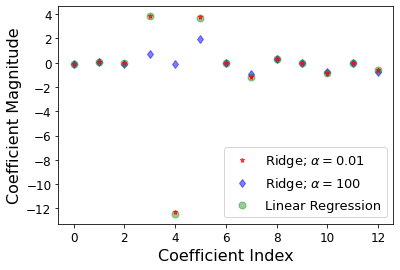

In [ ]:
import matplotlib.pyplot as plt
import numpy as np 
import pandas as pd
import matplotlib
matplotlib.rcParams.update({'font.size': 12})
from sklearn.datasets import load_boston
#from sklearn.cross_validation import train_test_split
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge

boston=load_boston()
boston_df=pd.DataFrame(boston.data,columns=boston.feature_names)
#print boston_df.info()
# add another column that contains the house prices which in scikit learn datasets are considered as target
boston_df['Price']=boston.target
boston_df.head(10)
newX=boston_df.drop('Price',axis=1)
newY=boston_df['Price']
#print type(newY)# pandas core frame
X_train,X_test,y_train,y_test=train_test_split(newX,newY,test_size=0.3,random_state=3)

lr = LinearRegression()
lr.fit(X_train, y_train)

rr = Ridge(alpha=0.01) # higher the alpha value, more restriction on the coefficients; low alpha > more generalization, coefficients are barely
# restricted and in this case linear and ridge regression resembles
rr.fit(X_train, y_train)

rr100 = Ridge(alpha=100) #  comparison with alpha value
rr100.fit(X_train, y_train)

train_score=lr.score(X_train, y_train)
test_score=lr.score(X_test, y_test)
Ridge_train_score = rr.score(X_train,y_train)
Ridge_test_score = rr.score(X_test, y_test)
Ridge_train_score100 = rr100.score(X_train,y_train)
Ridge_test_score100 = rr100.score(X_test, y_test)
print("linear regression train score:", train_score)
print("linear regression test score:", test_score)
print("ridge regression train score low alpha:", Ridge_train_score)
print("ridge regression test score low alpha:", Ridge_test_score)
print("ridge regression train score high alpha:", Ridge_train_score100)
print("ridge regression test score high alpha:", Ridge_test_score100)
plt.plot(rr.coef_,alpha=0.7,linestyle='none',marker='*',markersize=5,color='red',label=r'Ridge; $\alpha = 0.01$',zorder=7) # zorder for ordering the markers
plt.plot(rr100.coef_,alpha=0.5,linestyle='none',marker='d',markersize=6,color='blue',label=r'Ridge; $\alpha = 100$') # alpha here is for transparency
plt.plot(lr.coef_,alpha=0.4,linestyle='none',marker='o',markersize=7,color='green',label='Linear Regression')
plt.xlabel('Coefficient Index',fontsize=16)
plt.ylabel('Coefficient Magnitude',fontsize=16)
plt.legend(fontsize=13,loc=4)
plt.show()

linear regression train score: 0.7419034960343789
linear regression test score: 0.7147895265576851
Lasso regression train score low alpha: 0.7414845253242521
Lasso regression test score low alpha: 0.7096270988778383
Lasso regression train score high alpha: 0.22175771924133436
Lasso regression test score high alpha: 0.24781706709707008


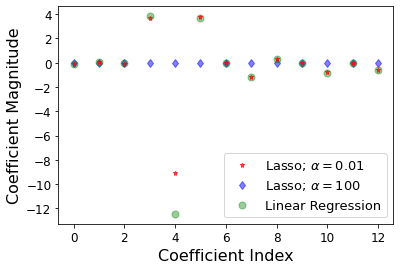

In [ ]:
from sklearn.linear_model import Lasso

lr = LinearRegression()
lr.fit(X_train, y_train)

rr = Lasso(alpha=0.01) # higher the alpha value, more restriction on the coefficients; low alpha > more generalization, coefficients are barely
# restricted and in this case linear and ridge regression resembles
rr.fit(X_train, y_train)

rr100 = Lasso(alpha=100) #  comparison with alpha value
rr100.fit(X_train, y_train)

train_score=lr.score(X_train, y_train)
test_score=lr.score(X_test, y_test)
Lasso_train_score = rr.score(X_train,y_train)
Lasso_test_score = rr.score(X_test, y_test)
Lasso_train_score100 = rr100.score(X_train,y_train)
Lasso_test_score100 = rr100.score(X_test, y_test)
print("linear regression train score:", train_score)
print("linear regression test score:", test_score)
print("Lasso regression train score low alpha:", Lasso_train_score)
print("Lasso regression test score low alpha:", Lasso_test_score)
print("Lasso regression train score high alpha:", Lasso_train_score100)
print("Lasso regression test score high alpha:", Lasso_test_score100)
plt.plot(rr.coef_,alpha=0.7,linestyle='none',marker='*',markersize=5,color='red',label=r'Lasso; $\alpha = 0.01$',zorder=7) # zorder for ordering the markers
plt.plot(rr100.coef_,alpha=0.5,linestyle='none',marker='d',markersize=6,color='blue',label=r'Lasso; $\alpha = 100$') # alpha here is for transparency
plt.plot(lr.coef_,alpha=0.4,linestyle='none',marker='o',markersize=7,color='green',label='Linear Regression')
plt.xlabel('Coefficient Index',fontsize=16)
plt.ylabel('Coefficient Magnitude',fontsize=16)
plt.legend(fontsize=13,loc=4)
plt.show()

## Diabetes Dataset

In [ ]:
import numpy as np
from sklearn import datasets

In [ ]:
diabetes_dataset=datasets.load_diabetes()

In [ ]:
diabetes_dataset

{'DESCR': '.. _diabetes_dataset:\n\nDiabetes dataset\n----------------\n\nTen baseline variables, age, sex, body mass index, average blood\npressure, and six blood serum measurements were obtained for each of n =\n442 diabetes patients, as well as the response of interest, a\nquantitative measure of disease progression one year after baseline.\n\n**Data Set Characteristics:**\n\n  :Number of Instances: 442\n\n  :Number of Attributes: First 10 columns are numeric predictive values\n\n  :Target: Column 11 is a quantitative measure of disease progression one year after baseline\n\n  :Attribute Information:\n      - Age\n      - Sex\n      - Body mass index\n      - Average blood pressure\n      - S1\n      - S2\n      - S3\n      - S4\n      - S5\n      - S6\n\nNote: Each of these 10 feature variables have been mean centered and scaled by the standard deviation times `n_samples` (i.e. the sum of squares of each column totals 1).\n\nSource URL:\nhttps://www4.stat.ncsu.edu/~boos/var.select/

In [ ]:
print(diabetes_dataset.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

  :Number of Instances: 442

  :Number of Attributes: First 10 columns are numeric predictive values

  :Target: Column 11 is a quantitative measure of disease progression one year after baseline

  :Attribute Information:
      - Age
      - Sex
      - Body mass index
      - Average blood pressure
      - S1
      - S2
      - S3
      - S4
      - S5
      - S6

Note: Each of these 10 feature variables have been mean centered and scaled by the standard deviation times `n_samples` (i.e. the sum of squares of each column totals 1).

Source URL:
https://www4.stat.ncsu.edu/~boos/var.select/diabetes.html

For more information see:
Bra

In [ ]:
diabetes_X=diabetes_dataset.data
print(diabetes_X.shape)

(442, 10)


In [ ]:
diabetes_y=diabetes_dataset.target
print(diabetes_y.shape)

(442,)


You also can simply use: diabetes_X, diabetes_y = datasets.load_diabetes(return_X_y=True)

In [ ]:
diabetes_X_train = diabetes_X[:-20]
diabetes_X_test  = diabetes_X[-20:]
diabetes_y_train = diabetes_y[:-20]
diabetes_y_test  = diabetes_y[-20:]

### Linear Regression

In [ ]:
from sklearn import linear_model
regr = linear_model.LinearRegression()
regr.fit(diabetes_X_train, diabetes_y_train)
print(regr.coef_)

[ 3.03499549e-01 -2.37639315e+02  5.10530605e+02  3.27736980e+02
 -8.14131709e+02  4.92814588e+02  1.02848452e+02  1.84606489e+02
  7.43519617e+02  7.60951722e+01]


In [ ]:
np.mean((regr.predict(diabetes_X_test) - diabetes_y_test)**2)#mean square error

2004.5676026898207

In [ ]:
regr.score(diabetes_X_test, diabetes_y_test) ## Explained variance score: 1 is perfect prediction and 0 means that there is no linear relationship between X and y.

0.5850753022690575

### Ridge and Lasso Regression

A solution in high-dimensional statistical learning is to shrink the regression coefficients to zero: any two randomly chosen set of observations are likely to be uncorrelated. This is called Ridge regression:

In [ ]:
regr = linear_model.Ridge(alpha=.1)# bias/variance tradeoff: the larger the ridge alpha parameter, the higher the bias and the lower the variance.
#The bias introduced by the ridge regression is called a regularization.

plt.figure() 
np.random.seed(0)

To improve the conditioning of the problem (i.e. mitigating the The curse of dimensionality), it would be interesting to select only the informative features and set non-informative ones, like feature 2 to 0. Ridge regression will decrease their contribution, but not set them to zero. Another penalization approach, called Lasso (least absolute shrinkage and selection operator), can set some coefficients to zero. Such methods are called sparse method

In [ ]:
regr = linear_model.Lasso()

alphas = np.logspace(-4, -1, 6)
print(alphas)
scores = [regr.set_params(alpha=alpha).fit(diabetes_X_train, diabetes_y_train).score(diabetes_X_test, diabetes_y_test) for alpha in alphas]
best_alpha = alphas[scores.index(max(scores))]
print("Best alpha:", best_alpha)
regr.alpha = best_alpha
regr.fit(diabetes_X_train, diabetes_y_train)
print(regr.coef_)

[0.0001     0.00039811 0.00158489 0.00630957 0.02511886 0.1       ]
Best alpha: 0.025118864315095794
[   0.         -212.43764548  517.19478111  313.77959962 -160.8303982
   -0.         -187.19554705   69.38229038  508.66011217   71.84239008]


# AUTO MPG Dataset

The Auto MPG dataset The dataset is available from the UCI Machine Learning Repository: https://archive.ics.uci.edu/ml/

In [ ]:
!wget http://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data

--2020-06-09 22:00:00--  http://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 30286 (30K) [application/x-httpd-php]
Saving to: ‘auto-mpg.data’

auto-mpg.data       100%[===================>]  29.58K  --.-KB/s    in 0.1s    

2020-06-09 22:00:01 (228 KB/s) - ‘auto-mpg.data’ saved [30286/30286]



In [ ]:
!mv ./auto-mpg.data ./auto-mpg.csv

In [ ]:
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
column_names = ['MPG','Cylinders','Displacement','Horsepower','Weight',
                'Acceleration', 'Model Year', 'Origin']
dataset_path = './auto-mpg.csv'
#https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_csv.html
#names: array, List of column names to use, If the file contains a header row, then you should explicitly pass header=0 to override the column names
#sep: Delimiter to use, default ‘,’, ' ' in the original csv file
#na_values: Additional strings to recognize as NA/NaN, ? in the original csv file
#comment: str, Indicates remainder of line should not be parsed
#skipinitialspacebool, default False, Skip spaces after delimiter.
raw_dataset = pd.read_csv(dataset_path, names=column_names,
                      na_values = "?", comment='\t',
                      sep=" ", skipinitialspace=True)

dataset = raw_dataset.copy()
dataset.tail()

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
393,27.0,4,140.0,86.0,2790.0,15.6,82,1
394,44.0,4,97.0,52.0,2130.0,24.6,82,2
395,32.0,4,135.0,84.0,2295.0,11.6,82,1
396,28.0,4,120.0,79.0,2625.0,18.6,82,1
397,31.0,4,119.0,82.0,2720.0,19.4,82,1


In [ ]:
dataset.isna().sum() # hoursepower has 6 missing value 

MPG             0
Cylinders       0
Displacement    0
Horsepower      6
Weight          0
Acceleration    0
Model Year      0
Origin          0
dtype: int64

In [ ]:
dataset.count
dataset = dataset.dropna() #drop those rows.
dataset.count

<bound method DataFrame.count of       MPG  Cylinders  Displacement  ...  Acceleration  Model Year  Origin
0    18.0          8         307.0  ...          12.0          70       1
1    15.0          8         350.0  ...          11.5          70       1
2    18.0          8         318.0  ...          11.0          70       1
3    16.0          8         304.0  ...          12.0          70       1
4    17.0          8         302.0  ...          10.5          70       1
..    ...        ...           ...  ...           ...         ...     ...
393  27.0          4         140.0  ...          15.6          82       1
394  44.0          4          97.0  ...          24.6          82       2
395  32.0          4         135.0  ...          11.6          82       1
396  28.0          4         120.0  ...          18.6          82       1
397  31.0          4         119.0  ...          19.4          82       1

[392 rows x 8 columns]>

In [ ]:
#The "Origin" column is categorical, not numeric. So convert that to a one-hot:
dataset['Origin'] = dataset['Origin'].map(lambda x: {1: 'USA', 2: 'Europe', 3: 'Japan'}.get(x))

In [ ]:
dataset

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
0,18.0,8,307.0,130.0,3504.0,12.0,70,USA
1,15.0,8,350.0,165.0,3693.0,11.5,70,USA
2,18.0,8,318.0,150.0,3436.0,11.0,70,USA
3,16.0,8,304.0,150.0,3433.0,12.0,70,USA
4,17.0,8,302.0,140.0,3449.0,10.5,70,USA
...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790.0,15.6,82,USA
394,44.0,4,97.0,52.0,2130.0,24.6,82,Europe
395,32.0,4,135.0,84.0,2295.0,11.6,82,USA
396,28.0,4,120.0,79.0,2625.0,18.6,82,USA


In [ ]:
#https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.get_dummies.html
dataset = pd.get_dummies(dataset, prefix='', prefix_sep='')#Convert categorical variable into dummy/indicator variables.
dataset.tail()

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Europe,Japan,USA
393,27.0,4,140.0,86.0,2790.0,15.6,82,0,0,1
394,44.0,4,97.0,52.0,2130.0,24.6,82,1,0,0
395,32.0,4,135.0,84.0,2295.0,11.6,82,0,0,1
396,28.0,4,120.0,79.0,2625.0,18.6,82,0,0,1
397,31.0,4,119.0,82.0,2720.0,19.4,82,0,0,1


In [ ]:
#Split the data into train and test
#https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.sample.html
train_dataset = dataset.sample(frac=0.8,random_state=0)
print(train_dataset.index)
test_dataset = dataset.drop(train_dataset.index)

Int64Index([146, 282,  69, 378, 331, 257, 310, 328, 125, 108,
            ...
            171,  70, 307,  49, 209, 281, 229, 150, 145, 182],
           dtype='int64', length=314)


In [ ]:
print("train dataset len: ", len(train_dataset))
print("test dataset len: ", len(test_dataset))

train dataset len:  314
test dataset len:  78


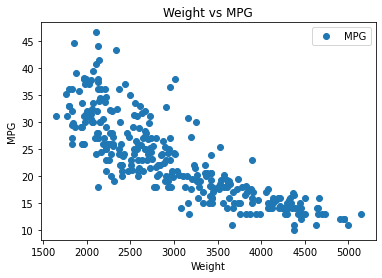

In [ ]:
train_dataset.plot(x='Weight', y='MPG', style='o')
plt.title('Weight vs MPG')  
plt.xlabel('Weight')  
plt.ylabel('MPG')  
plt.show()

/usr/local/lib/python3.6/dist-packages/statsmodels/tools/_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


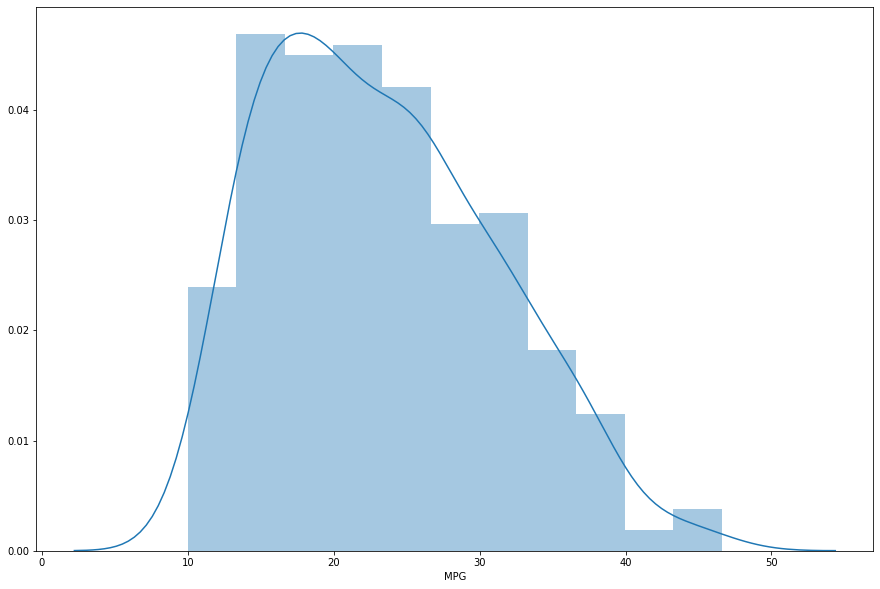

In [ ]:
import seaborn as sns
plt.figure(figsize=(15,10))
plt.tight_layout()
sns.distplot(train_dataset['MPG'])

## Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn import metrics #https://scikit-learn.org/stable/

In [ ]:
X = train_dataset['Weight'].values.reshape(-1,1)#column as 1
y = train_dataset['MPG'].values.reshape(-1,1)

In [ ]:
regressor = LinearRegression()  
regressor.fit(X, y) #training the algorithm

LinearRegression(copy_X=True, fit_intercept=True, n_jobs=None, normalize=False)

In [ ]:
#To retrieve the intercept:
print(regressor.intercept_)
#For retrieving the slope:
print(regressor.coef_)

[45.76121798]
[[-0.00750797]]


In [ ]:
X_test = test_dataset['Weight'].values.reshape(-1,1)#column as 1
y_test = test_dataset['MPG'].values.reshape(-1,1)

In [ ]:
y_pred = regressor.predict(X_test)

In [ ]:
dfcomp = pd.DataFrame({'Actual': y_test.flatten(), 'Predicted': y_pred.flatten()})
dfcomp

,Actual,Predicted
0,15.0,16.855547
1,10.0,11.111953
2,9.0,10.233521
3,25.0,29.033469
4,19.0,25.985235
...,...,...
73,34.0,27.779638
74,36.0,30.895445
75,34.0,28.905833
76,32.0,31.008064


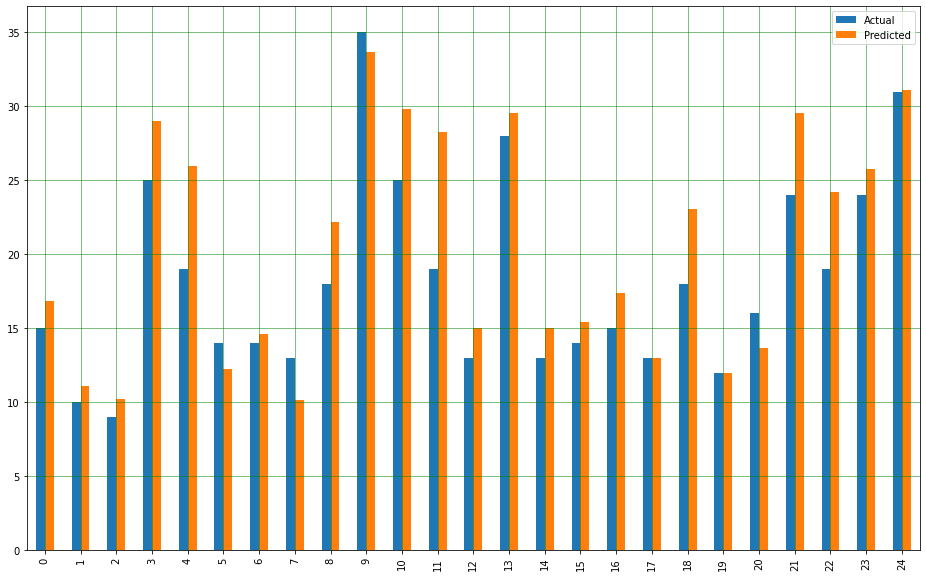

In [ ]:
df1 = dfcomp.head(25)
df1.plot(kind='bar',figsize=(16,10))
plt.grid(which='major', linestyle='-', linewidth='0.5', color='green')
plt.grid(which='minor', linestyle=':', linewidth='0.5', color='black')
plt.show()

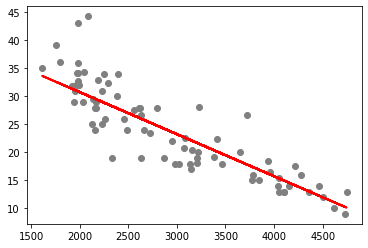

In [ ]:
plt.scatter(X_test, y_test,  color='gray')
plt.plot(X_test, y_pred, color='red', linewidth=2)
plt.show()

In [ ]:
print('Mean Absolute Error:', metrics.mean_absolute_error(y_test, y_pred))  
print('Mean Squared Error:', metrics.mean_squared_error(y_test, y_pred))  
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

Mean Absolute Error: 2.9344945081190428
Mean Squared Error: 15.33869208864019
Root Mean Squared Error: 3.916464233034714


## Polynomial Regression

In [ ]:
from sklearn.preprocessing import PolynomialFeatures #https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html

In [ ]:
polynomial_features= PolynomialFeatures(degree=2)
x_poly = polynomial_features.fit_transform(X_test)

In [ ]:
X_test

array([[3850.],
       [4615.],
       [4732.],
       [2228.],
       [2634.],
       [4464.],
       [4154.],
       [4746.],
       [3139.],
       [1613.],
       [2126.],
       [2330.],
       [4098.],
       [2164.],
       [4100.],
       [4042.],
       [3777.],
       [4363.],
       [3021.],
       [4499.],
       [4278.],
       [2158.],
       [2868.],
       [2660.],
       [1950.],
       [2451.],
       [3781.],
       [2489.],
       [3459.],
       [3221.],
       [2171.],
       [2984.],
       [3211.],
       [2945.],
       [2255.],
       [4215.],
       [3085.],
       [2035.],
       [1937.],
       [3651.],
       [1990.],
       [2155.],
       [4055.],
       [1985.],
       [1800.],
       [1985.],
       [3155.],
       [3070.],
       [3205.],
       [2560.],
       [2230.],
       [3140.],
       [2135.],
       [3955.],
       [4054.],
       [3940.],
       [1925.],
       [1975.],
       [3381.],
       [2800.],
       [2085.],
       [2290.],
       [

In [ ]:
x_poly

array([[1.0000000e+00, 3.8500000e+03, 1.4822500e+07],
       [1.0000000e+00, 4.6150000e+03, 2.1298225e+07],
       [1.0000000e+00, 4.7320000e+03, 2.2391824e+07],
       [1.0000000e+00, 2.2280000e+03, 4.9639840e+06],
       [1.0000000e+00, 2.6340000e+03, 6.9379560e+06],
       [1.0000000e+00, 4.4640000e+03, 1.9927296e+07],
       [1.0000000e+00, 4.1540000e+03, 1.7255716e+07],
       [1.0000000e+00, 4.7460000e+03, 2.2524516e+07],
       [1.0000000e+00, 3.1390000e+03, 9.8533210e+06],
       [1.0000000e+00, 1.6130000e+03, 2.6017690e+06],
       [1.0000000e+00, 2.1260000e+03, 4.5198760e+06],
       [1.0000000e+00, 2.3300000e+03, 5.4289000e+06],
       [1.0000000e+00, 4.0980000e+03, 1.6793604e+07],
       [1.0000000e+00, 2.1640000e+03, 4.6828960e+06],
       [1.0000000e+00, 4.1000000e+03, 1.6810000e+07],
       [1.0000000e+00, 4.0420000e+03, 1.6337764e+07],
       [1.0000000e+00, 3.7770000e+03, 1.4265729e+07],
       [1.0000000e+00, 4.3630000e+03, 1.9035769e+07],
       [1.0000000e+00, 3.021

In [ ]:
y_test.shape

(78, 1)

In [ ]:
x_poly.shape

(78, 3)

In [ ]:
model = LinearRegression()
model.fit(x_poly, y_test)


LinearRegression(copy_X=True, fit_intercept=True, n_jobs=None, normalize=False)

In [ ]:
model.coef_

array([[ 0.00000000e+00, -1.92427663e-02,  1.76575447e-06]])

In [ ]:
y_poly_pred = model.predict(x_poly)
rmse = np.sqrt(metrics.mean_squared_error(y_test,y_poly_pred))
print(rmse)

3.695197913223615


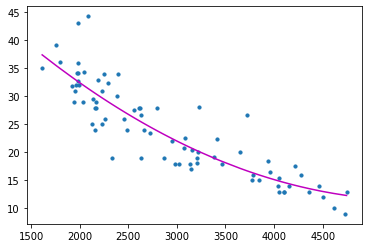

In [ ]:
import operator
plt.scatter(X_test, y_test, s=10)
# sort the values of x before line plot
sort_axis = operator.itemgetter(0)
sorted_zip = sorted(zip(X_test,y_poly_pred), key=sort_axis)
X_test, y_poly_pred = zip(*sorted_zip)
plt.plot(X_test, y_poly_pred, color='m')
plt.show()

In [ ]:
r2 = metrics.r2_score(y_test,y_poly_pred)
print(r2)

-1.8624589267151248


## Multiple Linear Regression

In [ ]:
#using sklearn to split the dataset
from sklearn.model_selection import train_test_split 
dataset.isnull().any()

MPG             False
Cylinders       False
Displacement    False
Horsepower      False
Weight          False
Acceleration    False
Model Year      False
Europe          False
Japan           False
USA             False
dtype: bool

In [ ]:
#MPG	Cylinders	Displacement	Horsepower	Weight	Acceleration	Model Year
columnname=['Cylinders', 'Displacement', 'Horsepower', 'Weight', 'Acceleration', 'Model Year']
Xm = dataset[columnname].values
ym = dataset['MPG'].values

In [ ]:
print(dataset.index)
print(dataset.columns)

Int64Index([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,
            ...
            388, 389, 390, 391, 392, 393, 394, 395, 396, 397],
           dtype='int64', length=392)
Index(['MPG', 'Cylinders', 'Displacement', 'Horsepower', 'Weight',
       'Acceleration', 'Model Year', 'Europe', 'Japan', 'USA'],
      dtype='object')


In [ ]:
dataset['MPG'].mean()

23.44591836734694

In [ ]:
Xm.shape

(392, 6)

In [ ]:
ym.shape

(392,)

In [ ]:
data_plt = pd.concat([dataset['MPG'], dataset['Cylinders']], axis=1)
data_plt

,MPG,Cylinders
0,18.0,8
1,15.0,8
2,18.0,8
3,16.0,8
4,17.0,8
...,...,...
393,27.0,4
394,44.0,4
395,32.0,4
396,28.0,4


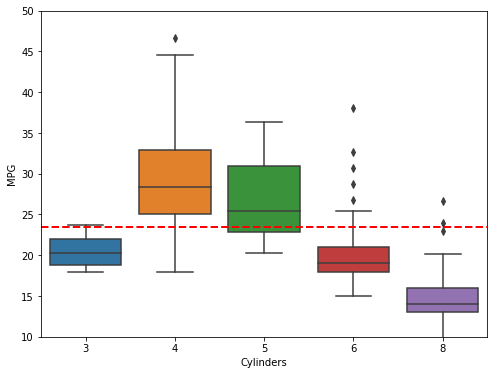

In [ ]:
f, ax = plt.subplots(figsize=(8, 6))
fig = sns.boxplot(x="Cylinders", y="MPG", data=data_plt)
fig.axis(ymin=10, ymax=50)
plt.axhline(dataset['MPG'].mean(),color='r',linestyle='dashed',linewidth=2)

In [ ]:
f.savefig("./boxfig.pdf")

In [ ]:
Xm_train, Xm_test, ym_train, ym_test = train_test_split(Xm, ym, test_size=0.2, random_state=0)

In [ ]:
mregressor = LinearRegression()  
mregressor.fit(Xm_train, ym_train)

LinearRegression(copy_X=True, fit_intercept=True, n_jobs=None, normalize=False)

In [ ]:
mregressor.coef_

array([-0.24724021,  0.00725555,  0.00398814, -0.00706142,  0.14878918,
        0.73921536])

In [ ]:
coeff_df = pd.DataFrame(mregressor.coef_, columnname, columns=['Coefficient'])  
coeff_df

,Coefficient
Cylinders,-0.247240
Displacement,0.007256
Horsepower,0.003988
Weight,-0.007061
Acceleration,0.148789
Model Year,0.739215


In [ ]:
ym_pred = mregressor.predict(Xm_test)

In [ ]:
dfm = pd.DataFrame({'Actual': ym_test, 'Predicted': ym_pred})
df1 = dfm.head(25)

In [ ]:
df1

,Actual,Predicted
0,28.0,27.273449
1,22.3,26.398770
2,12.0,10.422526
3,38.0,33.277905
4,33.8,32.107158
5,19.4,23.566027
6,38.1,33.390100
7,30.0,25.225206
8,20.0,21.040899
9,20.0,26.218960


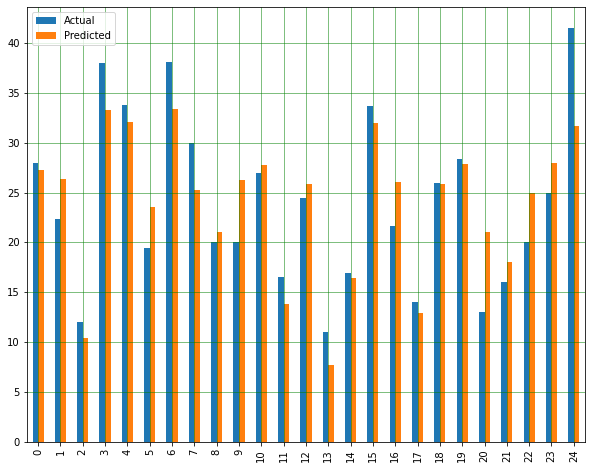

In [ ]:
fig=df1.plot(kind='bar',figsize=(10,8))
plt.grid(which='major', linestyle='-', linewidth='0.5', color='green')
plt.grid(which='minor', linestyle=':', linewidth='0.5', color='black')
plt.show()
fig.get_figure().savefig("bargraph2.pdf")

In [ ]:
print('Mean Absolute Error:', metrics.mean_absolute_error(ym_test, ym_pred))  
print('Mean Squared Error:', metrics.mean_squared_error(ym_test, ym_pred))  
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(ym_test, ym_pred)))

Mean Absolute Error: 2.6724608826273166
Mean Squared Error: 11.8782622888657
Root Mean Squared Error: 3.446485498136573


In [ ]:
print(metrics.r2_score(ym_test, ym_pred))

0.8088938602131776
